# Лабораторная работа № 3. Сбор данных через REST API

**Студент:** Подольский Ф. А., ПМИ-3-2025
**Вариант 5:** основной API — CoinGecko `/coins/markets` (пагинация `per_page`/`page`, жёсткий rate limit);
API обогащения — CoinGecko `/coins/{id}/market_chart`.
**Задача анализа:** капитализация и суточная волатильность топ-активов.

Данные предоставлены [CoinGecko](https://www.coingecko.com) — *Powered by CoinGecko*.

| Этап | Содержание |
|---|---|
| 1 | Изучение API: пробные запросы, паспорт API |
| 2 | HTTP-клиент: сессия, безопасный разбор ответа, ограничитель скорости, повторы, журнал |
| 3 | Пагинация: 400 записей `/coins/markets` за 4 страницы |
| 4 | Нормализация: `json_normalize(sep=...)`, типы, дубликаты, развёртывание `sparkline_in_7d.price` (`record_path` + `meta`) |
| 5 | Инкрементальность: отбор новых записей по водяному знаку из `state.json` |
| 6 | Обогащение: `/coins/{id}/market_chart` для топ-50, `merge` с проверкой числа строк |
| 7 | Контроль качества: полнота, дубликаты, типы, правила бизнес-логики |
| 8 | Сохранение: `data_raw.jsonl`, `data_clean.csv`, `collection_log.csv`, `state.json` |
| 9 | Повторный запуск — проверка инкрементальности |
| 10 | Демонстрация обработки 429 |
| 11 | Анализ: капитализация и суточная волатильность |
| 12 | Метрики для сравнения с no-code (n8n) |

Блокнот исполняется сверху вниз (**Run All** или `./run_real.sh`); полный прогон без ключа занимает 10–20 минут
(прогон 16.10.2026 — 18 мин) — почти всё это время уходит на паузы, которых требует лимит бесплатного API.

## Этап 1. Изучение API

Сначала — несколько пробных запросов «вручную», без обёрток: проверяются коды ответа,
заголовки, структура JSON и формат дат. По результатам заполняется паспорт API (ниже).

In [1]:
import os
import json
import time
from datetime import datetime, timezone

import requests

try:  # ключ можно положить в файл .env рядом с блокнотом (см. .env.example)
    from dotenv import load_dotenv
except ImportError:  # python-dotenv есть в requirements.txt; без него работают только переменные окружения
    load_dotenv = None
    print("python-dotenv не установлен: файл .env не читается, используются только переменные окружения")
if load_dotenv is not None:
    load_dotenv()

DEFAULT_BASE_URL = "https://api.coingecko.com/api/v3"
# COINGECKO_BASE_URL можно переопределить только для офлайн-тестов на имитации API
BASE_URL = os.getenv("COINGECKO_BASE_URL", DEFAULT_BASE_URL).rstrip("/")
API_KEY = os.getenv("COINGECKO_DEMO_API_KEY", "").strip()  # необязателен
USER_AGENT = "PSU-edu-crawler/1.0 (+https://github.com/Meta1rus/web-data-extraction; student lab)"


def mask(secret: str) -> str:
    # Секрет никогда не печатается целиком
    if not secret:
        return "<нет — keyless-режим>"
    if len(secret) <= 8:
        return "***"
    return secret[:4] + "…" + secret[-2:]


print("Базовый URL:", BASE_URL)
if BASE_URL != DEFAULT_BASE_URL:
    print("ВНИМАНИЕ: запросы идут НЕ в CoinGecko, а на тестовую имитацию — результаты не годятся для отчёта")
print("Demo-ключ: ", mask(API_KEY))

Базовый URL: https://api.coingecko.com/api/v3
Demo-ключ:  <нет — keyless-режим>


In [2]:
# Пробные запросы: намеренно простые requests.get, чтобы увидеть «сырой» ответ сервера
probe_headers = {"Accept": "application/json", "User-Agent": USER_AGENT}
if API_KEY:
    probe_headers["x-cg-demo-api-key"] = API_KEY

PROBE_PAUSE = float(os.getenv("PROBE_PAUSE", "6"))

probes = [
    ("ping",           "/ping",                          {}),
    ("markets p1",     "/coins/markets",                 {"vs_currency": "usd", "per_page": 3, "page": 1,
                                                          "sparkline": "true", "price_change_percentage": "24h,7d"}),
    ("markets пустая", "/coins/markets",                 {"vs_currency": "usd", "per_page": 250, "page": 100000}),
    ("market_chart",   "/coins/bitcoin/market_chart",    {"vs_currency": "usd", "days": 30, "interval": "daily"}),
    ("несущ. монета",  "/coins/no-such-coin-xyz/market_chart", {"vs_currency": "usd", "days": 30}),
]

def probe_get(url, params, attempts=3):
    """Простой GET для разведки. Сетевой обрыв (на реальном прогоне 16.10.2026 — SSL EOF) повторяем до 3 раз;
    если связи так и нет — возвращаем пустой ответ с кодом 0, чтобы разведка не роняла весь блокнот."""
    for attempt in range(1, attempts + 1):
        try:
            return requests.get(url, params=params, headers=probe_headers, timeout=15)
        except requests.RequestException as e:
            print(f"    сетевая ошибка (попытка {attempt}/{attempts}): {type(e).__name__}")
            if attempt < attempts:
                time.sleep(5 * attempt)
            last_error = e
    stub = requests.Response()
    stub.status_code, stub._content, stub.url = 0, b"", url
    stub.reason = f"нет ответа: {type(last_error).__name__}"
    return stub


probe_results = {}
for name, path, params in probes:
    t0 = time.perf_counter()
    r = probe_get(BASE_URL + path, params)
    dt = time.perf_counter() - t0
    probe_results[name] = r
    print(f"=== {name}: HTTP {r.status_code or r.reason}, {dt:.2f} c, {len(r.content)} байт")
    print("    Content-Type:", r.headers.get("Content-Type"))
    time.sleep(PROBE_PAUSE)   # пауза даже в пробах — у keyless-доступа лимит всего 5–30 запросов/мин

    сетевая ошибка (попытка 1/3): SSLError


=== ping: HTTP 200, 6.93 c, 34 байт
    Content-Type: application/json; charset=utf-8


=== markets p1: HTTP 200, 0.83 c, 12063 байт
    Content-Type: application/json; charset=utf-8


=== markets пустая: HTTP 200, 0.60 c, 2 байт
    Content-Type: application/json; charset=utf-8


    сетевая ошибка (попытка 1/3): SSLError


=== market_chart: HTTP 200, 16.69 c, 3244 байт
    Content-Type: application/json; charset=utf-8


    сетевая ошибка (попытка 1/3): SSLError


    сетевая ошибка (попытка 2/3): SSLError


=== несущ. монета: HTTP 404, 17.91 c, 26 байт
    Content-Type: application/json; charset=utf-8


In [3]:
# Все заголовки ответа — ищем среди них заголовки лимитов, кэширования, ETag и т.п.
for k, v in probe_results["markets p1"].headers.items():
    print(f"{k:35} {v}")

Date                                Fri, 16 Oct 2026 12:02:27 GMT
Content-Type                        application/json; charset=utf-8
Transfer-Encoding                   chunked
Connection                          keep-alive
x-frame-options                     SAMEORIGIN
x-xss-protection                    0
x-content-type-options              nosniff
x-permitted-cross-domain-policies   none
referrer-policy                     strict-origin-when-cross-origin
total                               18409
per-page                            3
Cache-Control                       max-age=30, public, must-revalidate, s-maxage=60
access-control-allow-origin         *
access-control-allow-methods        POST, PUT, DELETE, GET, OPTIONS
access-control-request-method       *
access-control-allow-headers        Origin, X-Requested-With, Content-Type, Accept, Authorization
access-control-expose-headers       link, per-page, total
vary                                Accept-Encoding, Origin
Content-Enco

In [4]:
# Заголовки, нужные для паспорта API: лимиты, пагинация, кэш, условные запросы
WANTED = {"retry-after", "total", "per-page", "link", "etag", "last-modified", "cache-control", "age",
          "expires", "cf-cache-status"}
hdrs = probe_results["markets p1"].headers
found = {k: v for k, v in hdrs.items() if "ratelimit" in k.lower() or k.lower() in WANTED}
print("Найдены:")
for k, v in found.items():
    print(f"  {k}: {v}")
if not any("ratelimit" in k.lower() for k in hdrs):
    print("Заголовков X-RateLimit-* в ответе нет — остаток лимита API не сообщает")
for h in ("Retry-After", "total", "per-page", "Link", "ETag"):
    print(f"  {h:12} {'есть' if h in hdrs else 'нет'}")

Найдены:
  total: 18409
  per-page: 3
  Cache-Control: max-age=30, public, must-revalidate, s-maxage=60
  etag: W/"dc239b594c9f743b9fb4b33a97892426"
  cf-cache-status: EXPIRED
Заголовков X-RateLimit-* в ответе нет — остаток лимита API не сообщает
  Retry-After  нет
  total        есть
  per-page     есть
  Link         нет
  ETag         есть


In [5]:
# Структура одной записи /coins/markets: поле → тип → пример
r = probe_results["markets p1"]
if r.status_code == 200 and r.json():
    rec = r.json()[0]
    for k, v in rec.items():
        sample = str(v)
        print(f"{k:42} {type(v).__name__:6} {sample[:60]}")
else:
    print("Проба не удалась:", r.status_code, r.text[:200], "— повторите ячейку с пробами через минуту")

id                                         str    bitcoin
symbol                                     str    btc
name                                       str    Bitcoin
image                                      str    https://coin-images.coingecko.com/coins/images/1/large/bitco
current_price                              int    82571
market_cap                                 int    1659375031304
market_cap_rank                            int    1
fully_diluted_valuation                    int    1659375031304
total_volume                               int    32299033108
high_24h                                   int    82508
low_24h                                    int    79806
price_change_24h                           float  1726.51
price_change_percentage_24h                float  2.13561
market_cap_change_24h                      int    34524331510
market_cap_change_percentage_24h           float  2.12477
circulating_supply                         float  20098843.0
total_supply

In [6]:
# Проверки, важные для пагинации, дат и ошибок
empty = probe_results["markets пустая"]
print("Страница за пределами данных:", empty.status_code, "→", empty.text[:100])

r = probe_results["market_chart"]
if r.status_code == 200:
    chart = r.json()
    print("\nКлючи market_chart:", list(chart))
    print("Точек prices:", len(chart["prices"]), "; первая:", chart["prices"][0], "; последняя:", chart["prices"][-1])
    for ts_ms, _ in (chart["prices"][0], chart["prices"][-1]):
        print("  как дата:", datetime.fromtimestamp(ts_ms / 1000, tz=timezone.utc))
else:
    print("market_chart:", r.status_code, r.text[:200])

bad = probe_results["несущ. монета"]
print("\nНесуществующая монета:", bad.status_code, bad.text[:200])

Страница за пределами данных: 200 → []

Ключи market_chart: ['prices', 'market_caps', 'total_volumes']
Точек prices: 31 ; первая: [1789603200000, 76146.81236783884] ; последняя: [1792152070000, 82561.51530727926]
  как дата: 2026-09-17 00:00:00+00:00
  как дата: 2026-10-16 12:01:10+00:00

Несуществующая монета: 404 {"error":"coin not found"}


### Паспорт API

| Поле | Значение |
|---|---|
| Название и базовый URL | CoinGecko API (Public / Demo), `https://api.coingecko.com/api/v3` |
| Версия и способ её указания | `v3` — в пути URL (`/api/v3/...`); справочник документации — v3.0.1 |
| Используемые эндпоинты | `GET /ping` — проверка доступности; `GET /coins/markets` — основной (список монет с рыночными данными); `GET /coins/{id}/market_chart` — обогащение (история цены, капитализации, объёма) |
| Аутентификация | Keyless (без ключа) либо бесплатный Demo-ключ в заголовке `x-cg-demo-api-key`. Ключ читается из переменной окружения `COINGECKO_DEMO_API_KEY` (файл `.env`), в выводе маскируется |
| Тип пагинации и параметры | Постраничная: `per_page` (1–250, по умолчанию 100) и `page` (с 1). Ссылки на следующую страницу (`Link`) нет; общее число монет приходит в заголовке `total` (18 409 на 16.10.2026), страница за пределами данных → 200 и `[]` → остановка по `total`, пустой / неполной странице или по `max_records`/`max_pages` |
| Документированные лимиты | Keyless: общий пул на IP, зависит от нагрузки — страница *Keyless Public API* называет ≈10–30 запросов/мин, статья поддержки — 5–15/мин. Demo: 30/мин по статье поддержки; актуальные документация и страница тарифов — 100/мин и 10 000 вызовов в месяц. При превышении — `429 Too Many Requests`. Ответы 4xx/5xx тоже расходуют лимит. Данные `/coins/markets` в бесплатных планах обновляются раз в 60 с |
| Заголовки лимитов в ответе | По выводу ячейки «Заголовки, нужные для паспорта API» (16.10.2026): `X-RateLimit-*` нет — остаток лимита API не сообщает; у ответа 200 есть `total` (18 409) и `per-page`, `Cache-Control: max-age=30, public, must-revalidate, s-maxage=60`, слабый `ETag`, `cf-cache-status` (Cloudflare); оба ответа 429 прогона пришли с `Retry-After: 60`. Документация эти заголовки не описывает; код учитывает `Retry-After` и `total` |
| Формат дат | `/coins/markets`: ISO 8601 в UTC (`last_updated`, `ath_date`, `atl_date`); `/market_chart`: Unix-время в миллисекундах, дневные точки — на 00:00 UTC, последняя точка — текущий момент |
| Ключ уникальности записи | `/coins/markets`: `id` монеты (строка, напр. `bitcoin`) в рамках одного снимка; в накопительной таблице — пара (`id`, `snapshot_date`). `/market_chart`: пара (`coin_id`, `timestamp`) |
| Наличие персональных данных | Нет: только агрегированные рыночные показатели криптоактивов |
| Ограничения условий использования | Атрибуция «Powered by CoinGecko» (п. 4.3 API Terms); запрещено продавать и перераспределять доступ к API (п. 4.1.6); кэш данных обновлять не реже раза в 24 ч (п. 6.1.1); при прекращении доступа данные удалить (п. 6.1.4, 10.4); соблюдать лимиты тарифа (п. 4.2); применимое право — Сингапур (п. 13.1) |

## Этап 2. HTTP-клиент: сессия, безопасный разбор, лимит скорости, повторы, журнал

Все дальнейшие запросы идут через одну функцию `request_json`. Реакция на ответ:

| Ответ | Действие |
|---|---|
| 2xx | проверить `Content-Type`, разобрать JSON |
| 304 Not Modified | страница не изменилась — взять её записи из `data_raw.jsonl` (условный запрос по `ETag`) |
| 429 Too Many Requests | ждать `Retry-After`, если сервер его прислал, иначе экспоненциальная задержка с джиттером; ограничитель скорости замедляется в 1,5 раза |
| 500, 502, 503, 504, таймаут, обрыв соединения | экспоненциальная задержка с джиттером |
| остальные 4xx (400, 401, 403, 404 …) | **без повторов**: исключение с кодом, URL и первыми 200 байтами тела |

Число попыток ограничено: `MAX_ATTEMPTS = 6` (1 основная + 5 повторов, задержки ≈3, 6, 12, 24, 48 с,
каждая — случайно от половины до полного значения). По документации CoinGecko запросы с ответами 4xx/5xx тоже расходуют
минутный лимит, поэтому повторять «на всякий случай» нельзя.

Каждая HTTP-попытка пишется в журнал (`collection_log.csv`): отметка времени UTC, прогон, этап, страница, URL, параметры,
номер попытки, код ответа, число записей, длительность, `Retry-After`, выдержанная пауза, примечание.

In [7]:
import random
from email.utils import parsedate_to_datetime
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

TIMEOUT = (5, 30)                    # (соединение, чтение), с — передаётся в КАЖДЫЙ запрос
MAX_ATTEMPTS = int(os.getenv("CG_MAX_ATTEMPTS", "6"))
BACKOFF_BASE = float(os.getenv("CG_BACKOFF_BASE", "3"))
BACKOFF_CAP = 60.0
RETRY_AFTER_CAP = 120.0              # защита от абсурдно большого Retry-After
RETRYABLE = {429, 500, 502, 503, 504}
# Пауза между запросами. Keyless: 5–30 запросов/мин в зависимости от нагрузки; Demo: 30–100/мин
MIN_INTERVAL = float(os.getenv("CG_MIN_INTERVAL", "2.5" if API_KEY else "6.5"))

PAGE_SIZE = 100                      # per_page
MAX_RECORDS = 400                    # ≥ 300 записей
MAX_PAGES = 5                        # предохранитель: при 100 на странице достаточно 4 (≥ 3 страниц)
ENRICH_TOP_N = int(os.getenv("CG_ENRICH_TOP", "50"))
CHART_DAYS = 30

OUT_DIR = Path(os.getenv("LAB3_OUT_DIR", "."))
OUT_DIR.mkdir(parents=True, exist_ok=True)
RAW_PATH = OUT_DIR / "data_raw.jsonl"
CLEAN_PATH = OUT_DIR / "data_clean.csv"
LOG_PATH = OUT_DIR / "collection_log.csv"
STATE_PATH = OUT_DIR / "state.json"

print(f"Пауза между запросами: {MIN_INTERVAL} с (≈ {60 / MIN_INTERVAL:.0f} запросов/мин), "
      f"попыток на запрос: {MAX_ATTEMPTS}, таймаут: {TIMEOUT}")
print("Файлы результата:", OUT_DIR.resolve())

Пауза между запросами: 6.5 с (≈ 9 запросов/мин), попыток на запрос: 6, таймаут: (5, 30)
Файлы результата: ~/Desktop/рабочий стол/Вуз/учеба/Инструменты автоматизирвоанного сбора данных в сети Интернет/solutions/lab3_podolskiy_5


In [8]:
def make_session() -> requests.Session:
    """Одна сессия на весь сбор: keep-alive, честный User-Agent, Accept; ключ — только в заголовке."""
    s = requests.Session()
    s.headers.update({"User-Agent": USER_AGENT, "Accept": "application/json"})
    if API_KEY:
        s.headers["x-cg-demo-api-key"] = API_KEY
    return s


session = make_session()
print({k: (mask(v) if k.lower() == "x-cg-demo-api-key" else v) for k, v in session.headers.items()})

{'User-Agent': 'PSU-edu-crawler/1.0 (+https://github.com/Meta1rus/web-data-extraction; student lab)', 'Accept-Encoding': 'gzip, deflate', 'Accept': 'application/json', 'Connection': 'keep-alive'}


In [9]:
class APIError(Exception):
    """Ошибка ответа API: код, URL и начало тела — всё, что нужно для разбора причины."""

    def __init__(self, message, status=None, url=None):
        super().__init__(message)
        self.status = status
        self.url = url


def body_preview(resp, n=200):
    return resp.content[:n].decode("utf-8", errors="replace")


def api_error(resp, prefix=""):
    return APIError(f"{prefix}HTTP {resp.status_code} {resp.reason} для {resp.url}; "
                    f"первые 200 байт тела: {body_preview(resp)!r}", resp.status_code, resp.url)


def parse_json(resp):
    """Безопасный разбор ответа: статус → Content-Type → JSON. Ошибка всегда содержит начало тела."""
    if resp.status_code >= 400:
        raise api_error(resp)
    ctype = resp.headers.get("Content-Type", "")
    if "json" not in ctype.lower():
        raise api_error(resp, f"Ожидался JSON, получен Content-Type {ctype!r}: ")
    try:
        return resp.json()
    except ValueError as e:
        raise api_error(resp, f"Некорректный JSON ({e}): ") from e

In [10]:
class RateLimiter:
    """Не чаще одного запроса в `interval` секунд. После 429 интервал увеличивается (до max_interval)."""

    def __init__(self, interval, max_interval=30.0):
        self.interval = interval
        self.max_interval = max_interval
        self._last = None

    def wait(self):
        if self._last is not None:
            delay = self.interval - (time.monotonic() - self._last)
            if delay > 0:
                time.sleep(delay)
        self._last = time.monotonic()

    def slow_down(self, factor=1.5):
        self.interval = min(self.max_interval, self.interval * factor)


limiter = RateLimiter(MIN_INTERVAL)   # один ограничитель на все запросы блокнота

In [11]:
COLLECTION_LOG = []        # журнал: одна строка = одна HTTP-попытка
_log_written = 0           # сколько строк журнала уже записано в collection_log.csv
LOG_COLUMNS = ["ts_utc", "run_id", "stage", "page", "url", "params", "attempt", "status", "n_records",
               "duration_s", "retry_after_s", "wait_s", "note"]


def parse_retry_after(value):
    """Retry-After: число секунд или HTTP-дата (RFC 9110). None — заголовка нет или он некорректен."""
    if not value:
        return None
    value = value.strip()
    if value.isdigit():
        return float(value)
    try:
        moment = parsedate_to_datetime(value)
    except (TypeError, ValueError):
        return None
    if moment.tzinfo is None:
        moment = moment.replace(tzinfo=timezone.utc)
    return max(0.0, (moment - datetime.now(timezone.utc)).total_seconds())


def backoff_delay(attempt, base=None):
    """Экспоненциальная задержка с «равным» джиттером: половина фиксирована, половина случайна."""
    base = BACKOFF_BASE if base is None else base
    d = min(BACKOFF_CAP, base * 2 ** (attempt - 1))
    return d / 2 + random.uniform(0, d / 2)


def count_records(data):
    if isinstance(data, list):
        return len(data)
    if isinstance(data, dict) and isinstance(data.get("prices"), list):
        return len(data["prices"])
    return None


def request_json(session, path, params=None, *, limiter=None, stage="", page=None, run_id="",
                 etag=None, max_attempts=None, backoff_base=None, log=None):
    """GET + безопасный разбор. Возвращает (data, resp); при 304 — (None, resp).

    Повторы — только для 429, 5xx и сетевых сбоев, не больше max_attempts попыток.
    Любой другой 4xx — сразу APIError, без повторов.
    """
    max_attempts = max_attempts or MAX_ATTEMPTS
    log = COLLECTION_LOG if log is None else log
    url = path if path.startswith("http") else BASE_URL + path
    headers = {"If-None-Match": etag} if etag else None
    params_txt = json.dumps(params or {}, ensure_ascii=False, sort_keys=True)   # ключа здесь нет — он в заголовке
    for attempt in range(1, max_attempts + 1):
        if limiter is not None:
            limiter.wait()
        row = {"ts_utc": datetime.now(timezone.utc).isoformat(timespec="milliseconds"), "run_id": run_id,
               "stage": stage, "page": page, "url": url, "params": params_txt, "attempt": attempt,
               "status": None, "n_records": None, "duration_s": None, "retry_after_s": None,
               "wait_s": None, "note": ""}
        log.append(row)
        last = attempt == max_attempts
        t0 = time.perf_counter()
        try:
            resp = session.get(url, params=params, headers=headers, timeout=TIMEOUT)
        except (requests.Timeout, requests.ConnectionError) as e:
            row["duration_s"] = round(time.perf_counter() - t0, 3)
            row["note"] = f"сетевая ошибка {type(e).__name__}"
            if last:
                raise APIError(f"{url}: сетевая ошибка после {attempt} попыток: {e}", None, url) from e
            row["wait_s"] = round(backoff_delay(attempt, backoff_base), 2)
            time.sleep(row["wait_s"])
            continue
        row["duration_s"] = round(time.perf_counter() - t0, 3)
        row["status"] = resp.status_code
        if resp.status_code == 304:
            row["note"] = "304: страница не изменилась (ETag)"
            return None, resp
        if resp.status_code < 400:
            data = parse_json(resp)              # проверит Content-Type и корректность JSON
            row["n_records"] = count_records(data)
            return data, resp
        if resp.status_code not in RETRYABLE:
            row["note"] = "4xx — повтор запрещён"
            raise api_error(resp)
        # 429 или 5xx — повторяем с задержкой
        retry_after = parse_retry_after(resp.headers.get("Retry-After"))
        row["retry_after_s"] = retry_after
        if resp.status_code == 429 and limiter is not None:
            limiter.slow_down()
        if last:
            row["note"] = "попытки исчерпаны"
            raise api_error(resp, f"После {attempt} попыток: ")
        if retry_after is not None:
            wait = min(retry_after, RETRY_AFTER_CAP) + random.uniform(0, 1)
            row["note"] = "ждём Retry-After"
        else:
            wait = backoff_delay(attempt, backoff_base)
            row["note"] = "экспоненциальная задержка с джиттером"
        row["wait_s"] = round(wait, 2)
        row["note"] += f"; тело: {body_preview(resp, 80)!r}"
        time.sleep(wait)
    raise APIError(f"{url}: не удалось получить ответ за {max_attempts} попыток", None, url)


def flush_log():
    """Дописывает в collection_log.csv строки журнала, которые ещё не записаны."""
    global _log_written
    rows = COLLECTION_LOG[_log_written:]
    if rows:
        df = pd.DataFrame(rows, columns=LOG_COLUMNS)
        for col in ("page", "attempt", "status", "n_records"):
            df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")
        df.to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(), index=False, encoding="utf-8")
    _log_written = len(COLLECTION_LOG)

In [12]:
# Проверка клиента: доступность API и реакция на 4xx (повторов быть не должно)
data, resp = request_json(session, "/ping", limiter=limiter, stage="check", run_id="check")
print("ping →", data)
try:
    request_json(session, "/coins/no-such-coin-xyz/market_chart", {"vs_currency": "usd", "days": 1},
                 limiter=limiter, stage="check", run_id="check")
except APIError as e:
    print("Ожидаемая ошибка 4xx:", e)
display(pd.DataFrame(COLLECTION_LOG)[["ts_utc", "stage", "url", "attempt", "status", "duration_s", "note"]])

ping → {'gecko_says': '(V3) To the Moon!'}


Ожидаемая ошибка 4xx: HTTP 404 Not Found для https://api.coingecko.com/api/v3/coins/no-such-coin-xyz/market_chart?vs_currency=usd&days=1; первые 200 байт тела: '{"error":"coin not found"}'


,ts_utc,stage,url,attempt,status,duration_s,note
0,2026-10-16T12:03:52.859+00:00,check,https://api.coingecko.com/api/v3/ping,1,NaN,1.133,сетевая ошибка SSLError
1,2026-10-16T12:03:59.360+00:00,check,https://api.coingecko.com/api/v3/ping,2,200.0,1.655,
2,2026-10-16T12:04:05.864+00:00,check,https://api.coingecko.com/api/v3/coins/no-such...,1,404.0,0.325,4xx — повтор запрещён


## Этап 3. Пагинация: сбор `/coins/markets`

CoinGecko не даёт ссылку на следующую страницу, а общее число монет сообщает только в заголовке `total` (в прогоне
16.10.2026 — 18 409), поэтому цикл держится на собственных предохранителях:

- номер следующей страницы вычисляется из **фактически полученного** числа записей (`received // per_page + 1`),
  а не «вслепую» `page += 1`;
- остановка: пустая страница; неполная страница (последняя); `total` из заголовка; `max_records`;
  `max_pages` — цикл `for` с ограниченным числом итераций, а не `while True`;
- паузы между запросами задаёт ограничитель скорости, ответы 429/5xx обрабатывает `request_json`.

Параметры: `per_page=100`, `max_records=400`, `max_pages=5` → 4 страницы по 100 записей. `sparkline=true` добавляет
7-дневный ряд цен (нужен на этапе 4), `price_change_percentage=24h,7d` — изменения цены за 24 ч и 7 дней.

**Условные запросы (бонус).** Если сервер вернул `ETag`, он сохраняется в `state.json`. При следующем запросе той же страницы
отправляется `If-None-Match`; ответ `304` значит «страница не изменилась» — её записи берутся из `data_raw.jsonl`,
тело заново не передаётся.

In [13]:
KEY = ["id", "snapshot_date"]          # ключ накопительной таблицы


def empty_watermark():
    return {"snapshot_date": None, "ids": [], "last_updated_max": None}


def load_state():
    """state.json: водяной знак (этап 5), ETag страниц, история прогонов."""
    state = {}
    if STATE_PATH.exists():
        with open(STATE_PATH, encoding="utf-8") as f:
            state = json.load(f)
    state.setdefault("watermark", empty_watermark())
    state.setdefault("etags", {})
    state.setdefault("runs", [])
    if state["watermark"]["snapshot_date"] and not CLEAN_PATH.exists():
        print("state.json есть, а data_clean.csv нет — водяной знак сброшен, данные будут собраны заново")
        state["watermark"] = empty_watermark()
    if state["etags"] and not RAW_PATH.exists():
        state["etags"] = {}               # без сырых данных ответ 304 не на что опереть
    return state


def save_state(state):
    tmp = STATE_PATH.with_name(STATE_PATH.name + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(state, f, ensure_ascii=False, indent=2)
    os.replace(tmp, STATE_PATH)           # атомарная замена: файл не останется полузаписанным


def append_raw(lines):
    with open(RAW_PATH, "a", encoding="utf-8") as f:
        for obj in lines:
            f.write(json.dumps(obj, ensure_ascii=False) + "\n")


def load_raw_page(run_id, page):
    """Записи страницы `page` из прогона `run_id` — нужны, когда сервер ответил 304."""
    out = []
    if RAW_PATH.exists():
        with open(RAW_PATH, encoding="utf-8") as f:
            for line in f:
                obj = json.loads(line)
                if obj.get("source") == "coins/markets" and obj.get("run_id") == run_id and obj.get("page") == page:
                    out.append(obj["record"])
    return out


def start_run():
    started = datetime.now(timezone.utc)
    return {"run_id": "run_" + started.strftime("%Y%m%dT%H%M%S") + f"{started.microsecond // 1000:03d}Z",
            "started": started,
            "t0": time.perf_counter(), "snapshot_date": started.date().isoformat(),
            "log_from": len(COLLECTION_LOG)}


CLEAN_COLUMNS = [
    "snapshot_date", "market_cap_rank", "id", "symbol", "name", "current_price", "market_cap",
    "fully_diluted_valuation", "total_volume", "high_24h", "low_24h", "price_change_24h",
    "price_change_percentage_24h", "price_change_percentage_24h_in_currency", "price_change_percentage_7d_in_currency",
    "market_cap_change_24h", "market_cap_change_percentage_24h", "circulating_supply", "total_supply", "max_supply",
    "ath", "ath_change_percentage", "ath_date", "atl", "atl_change_percentage", "atl_date",
    "roi_times", "roi_currency", "roi_percentage", "last_updated", "image",
    "spark_points", "vol_7d_sparkline_pct", "vol_30d_daily_pct", "n_daily_returns", "mcap_change_30d_pct",
    "avg_volume_30d", "chart_from", "chart_to", "enrich_error", "daily_volatility_pct", "vol_source",
    "range_24h_pct", "volume_to_mcap", "qc_flags", "page", "fetched_at", "run_id",
]
TEXT_STORED = ["snapshot_date", "id", "symbol", "name", "image", "roi_currency", "enrich_error", "vol_source",
               "qc_flags", "run_id"]


def read_clean():
    """data_clean.csv → DataFrame с восстановленными типами (даты в UTC, Int64, string)."""
    if not CLEAN_PATH.exists():
        return pd.DataFrame(columns=CLEAN_COLUMNS)
    # keep_default_na=False: символы вроде «nan» или «null» — это тикеры, а не пропуски
    df = pd.read_csv(CLEAN_PATH, keep_default_na=False, na_values=[""], dtype={c: "string" for c in TEXT_STORED})
    for col in DATE_COLS + ["fetched_at", "chart_from", "chart_to"]:
        df[col] = pd.to_datetime(df[col], utc=True, errors="coerce", format="ISO8601")
    for col in ("market_cap_rank", "spark_points", "n_daily_returns", "page"):
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")
    return df

In [14]:
def fetch_markets(session, limiter, run_id, etags, page_size=PAGE_SIZE, max_records=MAX_RECORDS, max_pages=MAX_PAGES):
    """Постраничный сбор /coins/markets.

    Возвращает (envelopes, pages): envelopes — сырые записи с метаданными (прогон, страница, время),
    pages — сводка по страницам.
    """
    if not 1 <= page_size <= 250:
        raise ValueError("per_page у CoinGecko — от 1 до 250")
    envelopes, pages = [], []
    received, total = 0, None
    for _ in range(max_pages):                          # предохранитель: не больше max_pages страниц
        page = received // page_size + 1                # следующая страница — по фактически полученному
        params = {"vs_currency": "usd", "order": "market_cap_desc", "per_page": page_size, "page": page,
                  "sparkline": "true", "price_change_percentage": "24h,7d"}
        cache_key = f"coins/markets|per_page={page_size}|page={page}"
        cached = etags.get(cache_key)
        t0 = time.perf_counter()
        data, resp = request_json(session, "/coins/markets", params, limiter=limiter, stage="markets",
                                  page=page, run_id=run_id, etag=cached["etag"] if cached else None)
        source_run = run_id
        if data is None:                                # 304 Not Modified
            data, source_run = load_raw_page(cached["run_id"], page), cached["run_id"]
            if not data:                                # сырых данных нет — запрашиваем страницу без условия
                data, resp = request_json(session, "/coins/markets", params, limiter=limiter,
                                          stage="markets", page=page, run_id=run_id)
                source_run = run_id
        if source_run == run_id and resp.headers.get("ETag"):
            etags[cache_key] = {"etag": resp.headers["ETag"], "run_id": run_id}
        if not isinstance(data, list):
            raise APIError(f"Ожидался список монет, получено {type(data).__name__}: {str(data)[:200]}")
        fetched_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
        pages.append({"page": page, "status": resp.status_code, "records": len(data), "data_from_run": source_run,
                      "seconds_with_pauses": round(time.perf_counter() - t0, 2)})
        if not data:
            print(f"Страница {page} пустая — данные закончились")
            break
        envelopes += [{"run_id": run_id, "source": "coins/markets", "page": page, "fetched_at": fetched_at,
                       "from_run": source_run, "record": rec} for rec in data]
        received += len(data)
        header_total = resp.headers.get("total", "")
        if header_total.isdigit():
            total = int(header_total)
        if len(data) < page_size:
            print(f"Страница {page} неполная ({len(data)} < {page_size}) — она последняя")
            break
        if total is not None and received >= total:
            print(f"Получены все записи: {received} из total={total}")
            break
        if received >= max_records:
            print(f"Достигнут max_records = {max_records}")
            break
    else:
        print(f"Сработал предохранитель max_pages = {max_pages}")
    return envelopes[:max_records], pages

In [15]:
state = load_state()
MAIN = start_run()
print("Прогон:", MAIN["run_id"], "| снимок за", MAIN["snapshot_date"], "(UTC)")
print("Водяной знак из state.json:", state["watermark"]["snapshot_date"], f"({len(state['watermark']['ids'])} монет)")

envelopes, pages = fetch_markets(session, limiter, MAIN["run_id"], state["etags"])
append_raw([e for e in envelopes if e["from_run"] == MAIN["run_id"]])

pages_df = pd.DataFrame(pages)
display(pages_df)
n_pages = int((pages_df["records"] > 0).sum())
print(f"Собрано записей: {len(envelopes)}, непустых страниц: {n_pages}")
print("Требование «≥ 300 записей и ≥ 3 страниц»:",
      "выполнено" if len(envelopes) >= 300 and n_pages >= 3 else "НЕ выполнено")

run_log = pd.DataFrame(COLLECTION_LOG[MAIN["log_from"]:])
display(run_log[["ts_utc", "page", "attempt", "status", "n_records", "duration_s", "retry_after_s", "wait_s", "note"]])

Прогон: run_20261016T120406237Z | снимок за 2026-10-16 (UTC)
Водяной знак из state.json: None (0 монет)


Достигнут max_records = 400


,page,status,records,data_from_run,seconds_with_pauses
0,1,200,100,run_20261016T120406237Z,6.82
1,2,200,100,run_20261016T120406237Z,6.31
2,3,200,100,run_20261016T120406237Z,6.46
3,4,200,100,run_20261016T120406237Z,67.00


Собрано записей: 400, непустых страниц: 4
Требование «≥ 300 записей и ≥ 3 страниц»: выполнено


,ts_utc,page,attempt,status,n_records,duration_s,retry_after_s,wait_s,note
0,2026-10-16T12:04:12.369+00:00,1,1,200,100.0,0.669,NaN,NaN,
1,2026-10-16T12:04:18.874+00:00,2,1,200,100.0,0.465,NaN,NaN,
2,2026-10-16T12:04:25.377+00:00,3,1,200,100.0,0.422,NaN,NaN,
3,2026-10-16T12:04:31.880+00:00,4,1,429,NaN,0.171,60.0,60.12,"ждём Retry-After; тело: '{""status"":{""error_cod..."
4,2026-10-16T12:05:32.173+00:00,4,2,200,100.0,0.626,NaN,NaN,


## Этап 4. Нормализация

1. `pd.json_normalize(records, sep="_")` раскладывает вложенный объект `roi` в столбцы `roi_times`, `roi_currency`, `roi_percentage`.
2. Типы: даты (`last_updated`, `ath_date`, `atl_date`) → `datetime64[…, UTC]`; числа → `float64`; ранг → `Int64`
   (целое с пропусками); текст → `string`.
3. Дубликаты по ключу. Пока запрашиваются страницы, рейтинг меняется, и монета с границы страниц может попасть на
   две страницы подряд (а соседняя — ни на одну). Остаётся одна запись на `id` — с самым поздним `last_updated`.
4. Вложенный массив `sparkline_in_7d.price` (≈168 почасовых цен за 7 дней) разворачивается в строки:
   `json_normalize(records, record_path=["sparkline_in_7d", "price"], meta=["id"])`. По этому ряду для **каждой**
   монеты оценивается суточная волатильность: σ почасовых лог-доходностей × √24.

In [16]:
DATE_COLS = ["last_updated", "ath_date", "atl_date"]
NUM_COLS = ["current_price", "market_cap", "fully_diluted_valuation", "total_volume", "high_24h", "low_24h",
            "price_change_24h", "price_change_percentage_24h", "price_change_percentage_24h_in_currency",
            "price_change_percentage_7d_in_currency", "market_cap_change_24h", "market_cap_change_percentage_24h",
            "circulating_supply", "total_supply", "max_supply", "ath", "ath_change_percentage", "atl",
            "atl_change_percentage", "roi_times", "roi_percentage"]
TEXT_COLS = ["id", "symbol", "name", "image", "roi_currency"]


def normalize_markets(envelopes, snapshot_date):
    """Сырые записи /coins/markets → плоская типизированная таблица, одна строка на монету."""
    df = pd.json_normalize([e["record"] for e in envelopes], sep="_")
    # массив sparkline разворачивается отдельно; столбец roi (None у монет без ROI) заменён roi_*
    df = df.drop(columns=[c for c in df.columns if c == "roi" or c.startswith("sparkline_in_7d")])
    for col in NUM_COLS + DATE_COLS + TEXT_COLS + ["market_cap_rank"]:
        if col not in df.columns:            # поле не пришло ни в одной записи — столбец всё равно нужен
            df[col] = np.nan
    df["page"] = [e["page"] for e in envelopes]
    df["run_id"] = [e["run_id"] for e in envelopes]
    df["fetched_at"] = pd.to_datetime([e["fetched_at"] for e in envelopes], utc=True)
    df["snapshot_date"] = snapshot_date
    for col in DATE_COLS:
        df[col] = pd.to_datetime(df[col], utc=True, errors="coerce")
    for col in NUM_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("float64")
    df["market_cap_rank"] = pd.to_numeric(df["market_cap_rank"], errors="coerce").astype("Int64")
    for col in TEXT_COLS + ["snapshot_date"]:
        df[col] = df[col].astype("string").str.strip()
    n_raw = len(df)
    dup_rows = df.loc[df["id"].duplicated(keep=False), ["id", "name", "page", "market_cap_rank", "last_updated"]]
    df = (df.sort_values(["id", "last_updated"])
            .drop_duplicates(subset="id", keep="last")
            .sort_values("market_cap_rank", na_position="last")
            .reset_index(drop=True))
    return df, n_raw, dup_rows


df_snap, n_raw, dup_rows = normalize_markets(envelopes, MAIN["snapshot_date"])
print(f"Записей до удаления дубликатов: {n_raw}, после: {len(df_snap)}; удалено: {n_raw - len(df_snap)}")
if len(dup_rows):
    print("Дубликаты (монета на границе страниц — рейтинг сдвинулся между запросами):")
    display(dup_rows)
display(df_snap[["market_cap_rank", "id", "symbol", "current_price", "market_cap", "last_updated",
                 "roi_times", "roi_currency", "page"]].head())

Записей до удаления дубликатов: 400, после: 399; удалено: 1
Дубликаты (монета на границе страниц — рейтинг сдвинулся между запросами):


,id,name,page,market_cap_rank,last_updated
299,kinetiq,Kinetiq,3,298,2026-10-16 12:02:43+00:00
300,kinetiq,Kinetiq,4,297,2026-10-16 12:04:59+00:00


,market_cap_rank,id,symbol,current_price,market_cap,last_updated,roi_times,roi_currency,page
0,1,bitcoin,btc,82455.000000,1.657267e+12,2026-10-16 12:03:53+00:00,NaN,<NA>,1
1,2,ethereum,eth,2471.810000,3.019043e+11,2026-10-16 12:03:53+00:00,43.30909,btc,1
2,3,tether,usdt,0.999202,1.835174e+11,2026-10-16 12:03:53+00:00,NaN,<NA>,1
3,4,binancecoin,bnb,730.590000,9.728935e+10,2026-10-16 12:03:53+00:00,NaN,<NA>,1
4,5,ripple,xrp,1.340000,8.478537e+10,2026-10-16 12:03:53+00:00,NaN,<NA>,1


In [17]:
def sparkline_long(envelopes):
    """Вложенный массив sparkline_in_7d.price → «длинная» таблица (id, номер точки, цена)."""
    latest = {}
    for e in envelopes:                       # одна запись на монету — как после дедупликации
        rec = e["record"]
        prev = latest.get(rec["id"])
        if prev is None or str(rec.get("last_updated") or "") >= str(prev.get("last_updated") or ""):
            latest[rec["id"]] = rec
    with_spark = [r for r in latest.values() if (r.get("sparkline_in_7d") or {}).get("price")]
    if not with_spark:
        return pd.DataFrame(columns=["id", "point", "price"])
    long = pd.json_normalize(with_spark, record_path=["sparkline_in_7d", "price"], meta=["id"])
    long = long.rename(columns={0: "price"})
    long["id"] = long["id"].astype("string")
    long["price"] = pd.to_numeric(long["price"], errors="coerce")
    long["point"] = long.groupby("id").cumcount()
    return long[["id", "point", "price"]]


def sparkline_volatility(long):
    """σ суточной лог-доходности, %, по 7-дневному ряду: σ одного шага × √(24 / шаг в часах)."""
    rows = []
    for coin_id, grp in long.groupby("id", sort=False):
        step_h = 7 * 24 / max(len(grp) - 1, 1)          # при 168 точках шаг ≈ 1 ч
        p = grp["price"].dropna()
        p = p[p > 0].to_numpy()
        vol = np.nan
        if len(p) >= 48:                                # меньше двух суток точек — оценка ненадёжна
            vol = float(np.diff(np.log(p)).std(ddof=1) * np.sqrt(24 / step_h) * 100)
        rows.append({"id": coin_id, "spark_points": len(p), "vol_7d_sparkline_pct": vol})
    out = pd.DataFrame(rows, columns=["id", "spark_points", "vol_7d_sparkline_pct"])
    out["id"] = out["id"].astype("string")
    return out


def add_sparkline_volatility(df, envelopes):
    long = sparkline_long(envelopes)
    vol = sparkline_volatility(long)
    n_before = len(df)
    df = df.merge(vol, on="id", how="left", validate="one_to_one")
    assert len(df) == n_before, "merge со sparkline изменил число строк"
    return df, long


df_snap, spark_long = add_sparkline_volatility(df_snap, envelopes)
print(f"Развёрнуто точек sparkline: {len(spark_long)} у {spark_long['id'].nunique()} монет "
      f"(≈{len(spark_long) / max(spark_long['id'].nunique(), 1):.0f} на монету)")
display(spark_long.head())
display(df_snap[["market_cap_rank", "id", "spark_points", "vol_7d_sparkline_pct"]].head(10))
print(df_snap.dtypes.to_string())

Развёрнуто точек sparkline: 65610 у 396 монет (≈166 на монету)


,id,point,price
0,bitcoin,0,83144.987240
1,bitcoin,1,82955.878627
2,bitcoin,2,82567.908266
3,bitcoin,3,82982.225318
4,bitcoin,4,82802.350697


,market_cap_rank,id,spark_points,vol_7d_sparkline_pct
0,1,bitcoin,168.0,1.744698
1,2,ethereum,168.0,2.427727
2,3,tether,168.0,0.026307
3,4,binancecoin,168.0,1.813602
4,5,ripple,168.0,2.820289
5,6,usd-coin,168.0,0.017841
6,7,solana,168.0,3.125264
7,8,tron,168.0,0.726400
8,9,figure-heloc,129.0,4.036609
9,10,zcash,168.0,5.407167


id                                                      string
symbol                                                  string
name                                                    string
image                                                   string
current_price                                          float64
market_cap                                             float64
market_cap_rank                                          Int64
fully_diluted_valuation                                float64
total_volume                                           float64
high_24h                                               float64
low_24h                                                float64
price_change_24h                                       float64
price_change_percentage_24h                            float64
market_cap_change_24h                                  float64
market_cap_change_percentage_24h                       float64
circulating_supply                                     

## Этап 5. Инкрементальность: отбор новых записей по водяному знаку

Накопительная таблица `data_clean.csv` хранит ежедневные снимки рынка; ключ — (`id`, `snapshot_date`), где
`snapshot_date` — дата запуска по UTC. Водяной знак в `state.json`:

```json
"watermark": {"snapshot_date": "2026-10-16", "ids": ["bitcoin", "ethereum", "…"], "last_updated_max": "2026-10-16T05:59:41+00:00"}
```

Правило: запись новая, если её `snapshot_date` позже водяного знака, либо дата та же, но монеты ещё нет в `ids`
(например, монета вошла в топ-400 между запусками). Поэтому повторный запуск в тот же день добавит 0 строк
или только действительно новые монеты, а обогащение — самая «дорогая» часть, до 50 запросов — выполняется только
для новых записей. Если `data_clean.csv` удалён, водяной знак сбрасывается, иначе данные никогда не собрались бы заново.

In [18]:
def select_new(df, state):
    """Строки, которых ещё нет в накопительной таблице, — по водяному знаку из state.json."""
    wm = state["watermark"]
    snap = df["snapshot_date"].iloc[0] if len(df) else None
    if wm["snapshot_date"] is None or (snap is not None and snap > wm["snapshot_date"]):
        is_new = pd.Series(True, index=df.index)
    elif snap == wm["snapshot_date"]:
        is_new = ~df["id"].isin(set(wm["ids"]))
    else:                                    # снимок старше водяного знака (например, сбились часы) — не пишем
        is_new = pd.Series(False, index=df.index)
    return df[is_new].copy()


df_new = select_new(df_snap, state)
print(f"Водяной знак: {state['watermark']['snapshot_date']}, монет в нём: {len(state['watermark']['ids'])}")
print(f"Получено в этом прогоне: {len(df_snap)}; новых по водяному знаку: {len(df_new)}")

Водяной знак: None, монет в нём: 0
Получено в этом прогоне: 399; новых по водяному знаку: 399


## Этап 6. Обогащение: `/coins/{id}/market_chart`

Для новых записей с рангом ≤ 50 запрашивается история за 30 дней с дневным шагом (`days=30&interval=daily`;
точки на 00:00 UTC, последняя точка — текущий момент, она отбрасывается как незакрытые сутки). Из ответа считаются:

- `vol_30d_daily_pct` — стандартное отклонение дневных лог-доходностей за 30 суток, % — «суточная волатильность»;
- `mcap_change_30d_pct` — изменение капитализации за период, %;
- `avg_volume_30d` — средний суточный объём торгов, USD.

Для остальных монет суточная волатильность берётся из 7-дневного sparkline (этап 4) — без дополнительных запросов.
Итоговое поле `daily_volatility_pct` — 30-дневная оценка, если она есть, иначе 7-дневная; источник — в `vol_source`.
Соединение — `merge(how="left", validate="one_to_one")` с проверкой числа строк до и после. Если обогащение монеты не удалось,
строка остаётся, а причина пишется в `enrich_error`.

In [19]:
ENRICH_COLS = ["id", "vol_30d_daily_pct", "n_daily_returns", "mcap_change_30d_pct", "avg_volume_30d",
               "chart_from", "chart_to", "enrich_error"]


def chart_features(chart):
    """Признаки из ответа market_chart: дневная волатильность, динамика капитализации, средний объём."""
    out = {"vol_30d_daily_pct": np.nan, "n_daily_returns": 0, "mcap_change_30d_pct": np.nan,
           "avg_volume_30d": np.nan, "chart_from": pd.NaT, "chart_to": pd.NaT}
    prices = pd.DataFrame(chart.get("prices") or [], columns=["ts_ms", "price"])
    if prices.empty:
        return out
    prices["ts"] = pd.to_datetime(prices["ts_ms"], unit="ms", utc=True)
    prices["day"] = prices["ts"].dt.floor("D")
    daily = prices.sort_values("ts").groupby("day", as_index=False).first()
    daily = daily[(daily["ts"] - daily["day"]) <= pd.Timedelta(hours=1)]   # только «полуночные» точки
    p = pd.to_numeric(daily["price"], errors="coerce")
    p = p[p > 0].to_numpy()
    r = np.diff(np.log(p))
    if len(r) >= 10:
        out["vol_30d_daily_pct"] = float(r.std(ddof=1) * 100)
    out["n_daily_returns"] = int(len(r))
    if len(daily):
        out["chart_from"], out["chart_to"] = daily["ts"].min(), daily["ts"].max()
    caps = pd.to_numeric(pd.Series([c[1] for c in chart.get("market_caps") or []], dtype="object"), errors="coerce")
    if len(caps) >= 2 and pd.notna(caps.iloc[0]) and caps.iloc[0] > 0:
        out["mcap_change_30d_pct"] = float((caps.iloc[-1] / caps.iloc[0] - 1) * 100)
    vols = pd.to_numeric(pd.Series([v[1] for v in chart.get("total_volumes") or []], dtype="object"), errors="coerce")
    if len(vols):
        out["avg_volume_30d"] = float(vols.mean())
    return out


def enrich(df_new, session, limiter, run_id, top_n=ENRICH_TOP_N):
    """market_chart для новых монет из топ-N + merge с проверкой числа строк + производные поля."""
    targets = df_new.loc[df_new["market_cap_rank"].le(top_n).fillna(False), "id"].tolist()
    print(f"Обогащение: {len(targets)} монет (ранг ≤ {top_n}), ≈{len(targets) * limiter.interval:.0f} с с учётом пауз")
    rows, raw_lines = [], []
    for i, coin_id in enumerate(targets, 1):
        try:
            chart, _ = request_json(session, f"/coins/{coin_id}/market_chart",
                                    {"vs_currency": "usd", "days": CHART_DAYS, "interval": "daily"},
                                    limiter=limiter, stage="market_chart", page=i, run_id=run_id)
        except APIError as e:               # монета остаётся без обогащения, причина сохраняется
            print(f"  {coin_id}: обогащение не удалось — {e}")
            rows.append({"id": coin_id, "enrich_error": str(e)[:200]})
            continue
        raw_lines.append({"run_id": run_id, "source": "coins/market_chart", "coin_id": coin_id,
                          "fetched_at": datetime.now(timezone.utc).isoformat(timespec="seconds"), "record": chart})
        rows.append({"id": coin_id, **chart_features(chart), "enrich_error": None})
        if i % 10 == 0:
            print(f"  … {i}/{len(targets)}")
    append_raw(raw_lines)
    enr = pd.DataFrame(rows, columns=ENRICH_COLS)
    enr["id"] = enr["id"].astype("string")
    for col in ("chart_from", "chart_to"):
        enr[col] = pd.to_datetime(enr[col], utc=True, errors="coerce")
    for col in ("vol_30d_daily_pct", "mcap_change_30d_pct", "avg_volume_30d"):
        enr[col] = pd.to_numeric(enr[col], errors="coerce").astype("float64")
    enr["n_daily_returns"] = pd.to_numeric(enr["n_daily_returns"], errors="coerce").astype("Int64")
    enr["enrich_error"] = enr["enrich_error"].astype("string")

    n_before = len(df_new)
    out = df_new.merge(enr, on="id", how="left", validate="one_to_one")
    print(f"Строк до merge: {n_before}, после: {len(out)}")
    assert len(out) == n_before, "merge изменил число строк — проверьте ключ"

    out["daily_volatility_pct"] = out["vol_30d_daily_pct"].fillna(out["vol_7d_sparkline_pct"])
    out["vol_source"] = pd.Series(pd.NA, index=out.index, dtype="string")
    out.loc[out["vol_7d_sparkline_pct"].notna(), "vol_source"] = "sparkline_7d"
    out.loc[out["vol_30d_daily_pct"].notna(), "vol_source"] = "market_chart_30d"
    out["range_24h_pct"] = (out["high_24h"] - out["low_24h"]) / out["current_price"] * 100
    out["volume_to_mcap"] = out["total_volume"] / out["market_cap"].where(out["market_cap"] > 0)
    return out


df_new = enrich(df_new, session, limiter, MAIN["run_id"])
enriched = df_new["vol_source"].eq("market_chart_30d").fillna(False)
print(f"Обогащено market_chart: {int(enriched.sum())}; ошибок обогащения: {int(df_new['enrich_error'].notna().sum())}")
display(df_new.loc[enriched, ["market_cap_rank", "id", "current_price", "market_cap", "vol_30d_daily_pct",
                              "vol_7d_sparkline_pct", "n_daily_returns", "mcap_change_30d_pct"]].head(10))

Обогащение: 50 монет (ранг ≤ 50), ≈488 с с учётом пауз


  … 10/50


  … 20/50


  … 30/50


  … 40/50


  … 50/50
Строк до merge: 399, после: 399
Обогащено market_chart: 50; ошибок обогащения: 0


,market_cap_rank,id,current_price,market_cap,vol_30d_daily_pct,vol_7d_sparkline_pct,n_daily_returns,mcap_change_30d_pct
0,1,bitcoin,82455.000000,1.657267e+12,1.995742,1.744698,29,8.281168
1,2,ethereum,2471.810000,3.019043e+11,2.307071,2.427727,29,2.339889
2,3,tether,0.999202,1.835174e+11,0.016469,0.026307,29,0.105371
3,4,binancecoin,730.590000,9.728935e+10,1.806853,1.813602,29,0.686793
4,5,ripple,1.340000,8.478537e+10,3.003637,2.820289,29,3.794146
5,6,usd-coin,0.999829,7.249794e+10,0.008658,0.017841,29,-1.506812
6,7,solana,106.330000,6.265915e+10,3.229758,3.125264,29,8.198092
7,8,tron,0.335429,3.186603e+10,0.618286,0.726400,29,0.065383
8,9,figure-heloc,1.031000,2.466013e+10,2.883074,4.036609,29,6.220567
9,10,zcash,1228.280000,2.086651e+10,5.639337,5.407167,29,-7.765116


## Этап 7. Контроль качества

- полнота каждого поля, %;
- дубликаты по ключу (`id`, `snapshot_date`) — после этапа 4 должно быть 0;
- типы: даты — `datetime64[…, UTC]`, числа — `float64` / `Int64`;
- правила бизнес-логики. Нарушение не удаляет строку, а записывается в столбец `qc_flags` (решение об исключении — за аналитиком):

| Код | Правило | Смысл |
|---|---|---|
| R1 | `current_price > 0` | цена актива не может быть нулевой или отрицательной |
| R2 | `market_cap ≥ 0` и `total_volume ≥ 0` | денежные величины неотрицательны |
| R3 | `low_24h ≤ current_price ≤ high_24h` (допуск 1 %) | текущая цена — внутри суточного диапазона |
| R4 | `circulating_supply ≤ total_supply ≤ max_supply` (допуск 0,1 %) | иерархия эмиссии |
| R5 | `market_cap ≈ current_price × circulating_supply` (± 5 %) | определение капитализации |
| R6 | по возрастанию `market_cap_rank` капитализация не растёт (допуск 0,1 %) | ранг — это порядок по капитализации |
| R7 | `0 ≤ daily_volatility_pct < 100` | суточная σ больше 100 % — признак ошибки данных |

Полнота заведомо неполная у `max_supply` (у многих монет эмиссия не ограничена), `roi_*` (ROI считается только для монет
с ICO) и полей обогащения (только топ-50) — это свойство данных, а не ошибка сбора.

In [20]:
def business_rules(df):
    """Возвращает (таблица правил, флаги нарушений по строкам)."""
    p, mc, vol = df["current_price"], df["market_cap"], df["total_volume"]
    lo, hi = df["low_24h"], df["high_24h"]
    cs, ts, ms = df["circulating_supply"], df["total_supply"], df["max_supply"]
    order = df.sort_values(["snapshot_date", "market_cap_rank"])
    prev_mc = order.groupby("snapshot_date")["market_cap"].shift(1).reindex(df.index)
    dv = df["daily_volatility_pct"]
    checks = {   # код: (описание, к каким строкам применимо, условие выполнено)
        "R1": ("цена > 0", p.notna(), p > 0),
        "R2": ("капитализация и объём ≥ 0", mc.notna() & vol.notna(), (mc >= 0) & (vol >= 0)),
        "R3": ("low_24h ≤ цена ≤ high_24h (±1 %)", p.notna() & lo.notna() & hi.notna(),
               (p >= lo * 0.99) & (p <= hi * 1.01)),
        "R4": ("circulating ≤ total ≤ max (±0,1 %)", cs.notna() & ts.notna(),
               (cs <= ts * 1.001) & (ms.isna() | (ts <= ms * 1.001))),
        "R5": ("market_cap ≈ цена × circulating (±5 %)", mc.gt(0) & p.notna() & cs.gt(0),
               ((p * cs / mc) - 1).abs() <= 0.05),
        "R6": ("капитализация не растёт с рангом (±0,1 %)",
               df["market_cap_rank"].notna() & mc.notna() & prev_mc.notna(), ~(mc > prev_mc * 1.001)),
        "R7": ("0 ≤ суточная σ < 100 %", dv.notna(), (dv >= 0) & (dv < 100)),
    }
    table, flags = [], pd.Series("", index=df.index, dtype="string")
    for code_, (title, applicable, ok) in checks.items():
        applicable = applicable.fillna(False).astype(bool)
        bad = applicable & ~ok.fillna(False).astype(bool)
        table.append({"код": code_, "правило": title, "проверено строк": int(applicable.sum()),
                      "нарушений": int(bad.sum()),
                      "доля нарушений, %": round(100 * bad.sum() / max(int(applicable.sum()), 1), 2)})
        flags = flags.where(~bad, flags + code_ + ";")
    return pd.DataFrame(table), flags.where(flags != "", "ok")


def quality_report(df, title):
    print(f"=== Контроль качества: {title} — {len(df)} строк ===")
    summary = pd.DataFrame({"тип": df.dtypes.astype(str),
                            "заполнено": df.notna().sum(),
                            "полнота, %": (df.notna().mean() * 100).round(1)})
    display(summary)
    dups = int(df.duplicated(subset=KEY).sum())
    print(f"Дубликатов по ключу {KEY}: {dups}")
    bad_dates = [c for c in DATE_COLS if not (isinstance(df[c].dtype, pd.DatetimeTZDtype) and str(df[c].dt.tz) == "UTC")]
    bad_nums = [c for c in NUM_COLS + ["market_cap_rank"] if not pd.api.types.is_numeric_dtype(df[c])]
    print("Даты — datetime с часовым поясом UTC:", "да" if not bad_dates else f"НЕТ: {bad_dates}")
    print("Числовые поля — числового типа:", "да" if not bad_nums else f"НЕТ: {bad_nums}")
    rules, flags = business_rules(df)
    display(rules)
    return summary, rules, flags, dups


def md_table(df):
    """DataFrame → таблица Markdown (для вставки в report.md)."""
    def fmt(v):
        if isinstance(v, float):
            return f"{v:.2f}".rstrip("0").rstrip(".") if pd.notna(v) else ""
        return "" if v is pd.NA or v is None else str(v)
    lines = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


if len(df_new):
    q_summary, q_rules, q_flags, q_dups = quality_report(df_new, "новые записи этого прогона")
    df_new["qc_flags"] = q_flags
    print("Строк хотя бы с одним нарушением:", int((q_flags != "ok").sum()))
    viol = df_new.loc[q_flags != "ok", ["market_cap_rank", "id", "current_price", "low_24h", "high_24h",
                                         "market_cap", "circulating_supply", "total_supply", "max_supply", "qc_flags"]]
    display(viol.head(10))
else:   # новых строк нет (повторный запуск в тот же день) — проверяем сохранённый снимок
    stored = read_clean()
    stored = stored[stored["snapshot_date"] == stored["snapshot_date"].max()]
    q_summary, q_rules, _, q_dups = quality_report(stored, "сохранённый снимок (новых записей нет)")

=== Контроль качества: новые записи этого прогона — 399 строк ===


,тип,заполнено,"полнота, %"
id,string,399,100.0
symbol,string,399,100.0
name,string,399,100.0
image,string,399,100.0
current_price,float64,399,100.0
market_cap,float64,399,100.0
market_cap_rank,Int64,393,98.5
fully_diluted_valuation,float64,399,100.0
total_volume,float64,399,100.0
high_24h,float64,399,100.0


Дубликатов по ключу ['id', 'snapshot_date']: 0
Даты — datetime с часовым поясом UTC: да
Числовые поля — числового типа: да


,код,правило,проверено строк,нарушений,"доля нарушений, %"
0,R1,цена > 0,399,0,0.00
1,R2,капитализация и объём ≥ 0,399,0,0.00
2,R3,low_24h ≤ цена ≤ high_24h (±1 %),399,9,2.26
3,R4,"circulating ≤ total ≤ max (±0,1 %)",399,6,1.50
4,R5,market_cap ≈ цена × circulating (±5 %),399,0,0.00
5,R6,"капитализация не растёт с рангом (±0,1 %)",392,12,3.06
6,R7,0 ≤ суточная σ < 100 %,392,0,0.00


Строк хотя бы с одним нарушением: 26


,market_cap_rank,id,current_price,low_24h,high_24h,market_cap,circulating_supply,total_supply,max_supply,qc_flags
13,14,usds,0.999876,0.999620,1.000000,1.023583e+10,1.023809e+10,1.022672e+10,NaN,R4;
41,42,aave,163.840000,147.400000,165.350000,2.528094e+09,1.543625e+07,1.600000e+07,1.600000e+07,R6;
84,85,pi-network,0.081399,0.077263,0.081780,9.152186e+08,1.124313e+10,1.729701e+10,1.000000e+11,R6;
102,103,eutbl,1.190000,1.190000,1.200000,6.442016e+08,5.394612e+08,5.371792e+08,NaN,R4;
129,130,falcon-finance-ff,0.112511,0.108682,0.117687,3.762324e+08,3.343056e+09,1.000000e+10,1.000000e+10,R6;
135,136,unibase,0.131371,0.111874,0.129645,3.292205e+08,2.500000e+09,1.000000e+10,1.000000e+10,R3;
157,158,usdai,0.999079,0.997877,1.000000,2.654757e+08,2.657216e+08,2.620068e+08,NaN,R4;
168,169,iota,0.050211,0.044569,0.049180,2.361080e+08,4.696396e+09,5.005657e+09,NaN,R3;
201,202,vaulta,0.102864,0.093663,0.101516,1.722867e+08,1.673593e+09,2.100000e+09,2.100000e+09,R3;
233,234,havven,0.229481,0.212072,0.230947,1.333306e+08,5.809806e+08,5.814042e+08,NaN,R6;


## Этап 8. Сохранение

| Файл | Содержимое | Как пишется |
|---|---|---|
| `data_raw.jsonl` | сырые записи `/coins/markets` и ответы `/market_chart` в том виде, в каком пришли; у каждой строки — `run_id`, источник, страница, время | дописывание |
| `data_clean.csv` | нормализованная обогащённая таблица, ключ (`id`, `snapshot_date`), UTF-8 | слияние со старыми строками без дубликатов ключа, атомарная запись |
| `collection_log.csv` | журнал HTTP-попыток | дописывание |
| `state.json` | водяной знак, `ETag` страниц, сводка каждого прогона | атомарная перезапись |

In [21]:
def save_clean(df_new):
    """Добавляет новые строки в data_clean.csv; ключ (id, snapshot_date) остаётся уникальным."""
    old = read_clean()
    new = df_new.reindex(columns=CLEAN_COLUMNS)
    combined = pd.concat([old, new], ignore_index=True) if len(old) and len(new) else (old if len(old) else new)
    n_before = len(combined)
    combined = combined.drop_duplicates(subset=KEY, keep="first")
    tmp = CLEAN_PATH.with_name(CLEAN_PATH.name + ".tmp")
    combined.to_csv(tmp, index=False, encoding="utf-8")
    os.replace(tmp, CLEAN_PATH)
    return len(combined), n_before - len(combined)


def finish_run(ctx, state, pages, df_snap, df_new, n_raw):
    """Сохранение результата прогона: таблица, водяной знак, сводка, журнал."""
    rows_total, dropped = save_clean(df_new)
    wm = state["watermark"]
    if len(df_new):
        if wm["snapshot_date"] != ctx["snapshot_date"]:
            wm.update(snapshot_date=ctx["snapshot_date"], ids=[])
        wm["ids"] = sorted(set(wm["ids"]) | set(df_new["id"].astype(str)))
        lu = df_new["last_updated"].max()
        if pd.notna(lu):
            wm["last_updated_max"] = max(v for v in (wm.get("last_updated_max"), lu.isoformat()) if v)
    log = pd.DataFrame(COLLECTION_LOG[ctx["log_from"]:], columns=LOG_COLUMNS)
    status = pd.to_numeric(log["status"], errors="coerce")
    summary = {
        "run_id": ctx["run_id"], "started_utc": ctx["started"].isoformat(timespec="seconds"),
        "duration_s": round(time.perf_counter() - ctx["t0"], 1),
        "http_attempts": int(len(log)),
        "pages": int(sum(1 for p in pages if p["records"] > 0)),
        "fetched_records": int(n_raw), "unique_records": int(len(df_snap)), "new_records": int(len(df_new)),
        "enriched": int(df_new["vol_30d_daily_pct"].notna().sum()) if len(df_new) else 0,
        "retries": int((pd.to_numeric(log["attempt"]) > 1).sum()),
        "status_429": int((status == 429).sum()), "status_5xx": int((status >= 500).sum()),
        "status_304": int((status == 304).sum()), "network_errors": int(log["note"].str.startswith("сетевая").sum()),
        "rows_in_clean_table": int(rows_total),
    }
    state["runs"].append(summary)
    save_state(state)
    flush_log()
    return summary


summary1 = finish_run(MAIN, state, pages, df_snap, df_new, n_raw)
print(json.dumps(summary1, ensure_ascii=False, indent=2))
for p in (RAW_PATH, CLEAN_PATH, LOG_PATH, STATE_PATH):
    print(f"{p.name:20} {p.stat().st_size / 1024:9.1f} КБ")
with open(RAW_PATH, encoding="utf-8") as f:
    print("Строк в data_raw.jsonl:", sum(1 for _ in f))

{
  "run_id": "run_20261016T120406237Z",
  "started_utc": "2026-10-16T12:04:06+00:00",
  "duration_s": 844.8,
  "http_attempts": 56,
  "pages": 4,
  "fetched_records": 400,
  "unique_records": 399,
  "new_records": 399,
  "enriched": 50,
  "retries": 2,
  "status_429": 2,
  "status_5xx": 0,
  "status_304": 0,
  "network_errors": 0,
  "rows_in_clean_table": 399
}
data_raw.jsonl          1900.1 КБ
data_clean.csv           222.7 КБ
collection_log.csv        13.1 КБ
state.json                 9.3 КБ
Строк в data_raw.jsonl: 450


## Этап 9. Повторный запуск — проверка инкрементальности

Тот же конвейер целиком одной функцией. При запуске в тот же день (UTC) ожидается: новых записей — 0 (или только монеты,
вошедшие в топ-400 между запусками), запросов к `/market_chart` — 0 (или только для таких монет). Страницы, не изменившиеся с
прошлого запроса, сервер может вернуть кодом 304 — тогда их тело не передаётся.

In [22]:
def run_pipeline():
    """Полный прогон: сбор → нормализация → отбор новых → обогащение → качество → сохранение."""
    state = load_state()
    ctx = start_run()
    envelopes, pages = fetch_markets(session, limiter, ctx["run_id"], state["etags"])
    append_raw([e for e in envelopes if e["from_run"] == ctx["run_id"]])
    df_snap, n_raw, _ = normalize_markets(envelopes, ctx["snapshot_date"])
    df_snap, _ = add_sparkline_volatility(df_snap, envelopes)
    df_new = select_new(df_snap, state)
    print(f"Получено: {len(df_snap)}, новых по водяному знаку: {len(df_new)}")
    df_new = enrich(df_new, session, limiter, ctx["run_id"])
    if len(df_new):
        _, _, flags, _ = quality_report(df_new, "новые записи повторного прогона")
        df_new["qc_flags"] = flags
    return finish_run(ctx, state, pages, df_snap, df_new, n_raw)


summary2 = run_pipeline()
runs = pd.DataFrame(load_state()["runs"])
display(runs.tail(2).set_index("run_id").T)
if summary2["new_records"] == 0:
    print("Повторный прогон добавил 0 строк и не делал запросов обогащения — инкрементальность работает.")
else:
    print(f"Повторный прогон добавил {summary2['new_records']} действительно новых строк "
          f"(другой день UTC или новые монеты в топ-{MAX_RECORDS}).")

Достигнут max_records = 400
Получено: 400, новых по водяному знаку: 2
Обогащение: 0 монет (ранг ≤ 50), ≈0 с с учётом пауз
Строк до merge: 2, после: 2
=== Контроль качества: новые записи повторного прогона — 2 строк ===


,тип,заполнено,"полнота, %"
id,string,2,100.0
symbol,string,2,100.0
name,string,2,100.0
image,string,2,100.0
current_price,float64,2,100.0
market_cap,float64,2,100.0
market_cap_rank,Int64,2,100.0
fully_diluted_valuation,float64,2,100.0
total_volume,float64,2,100.0
high_24h,float64,2,100.0


Дубликатов по ключу ['id', 'snapshot_date']: 0
Даты — datetime с часовым поясом UTC: да
Числовые поля — числового типа: да


,код,правило,проверено строк,нарушений,"доля нарушений, %"
0,R1,цена > 0,2,0,0.0
1,R2,капитализация и объём ≥ 0,2,0,0.0
2,R3,low_24h ≤ цена ≤ high_24h (±1 %),2,0,0.0
3,R4,"circulating ≤ total ≤ max (±0,1 %)",2,0,0.0
4,R5,market_cap ≈ цена × circulating (±5 %),2,0,0.0
5,R6,"капитализация не растёт с рангом (±0,1 %)",1,0,0.0
6,R7,0 ≤ суточная σ < 100 %,2,0,0.0


run_id,run_20261016T120406237Z,run_20261016T121811006Z
started_utc,2026-10-16T12:04:06+00:00,2026-10-16T12:18:11+00:00
duration_s,844.8,59.0
http_attempts,56,4
pages,4,4
fetched_records,400,400
unique_records,399,400
new_records,399,2
enriched,50,0
retries,2,0
status_429,2,0


Повторный прогон добавил 2 действительно новых строк (другой день UTC или новые монеты в топ-400).


## Этап 10. Демонстрация обработки 429 (обязательна для варианта 5)

Короткая серия запросов **без ограничителя скорости** к `/coins/markets?per_page=1&page=k` (разные `page`, чтобы ответ
не пришёл из кэша CDN). Предохранитель — не больше 25 HTTP-запросов вместе с повторами. Серия останавливается,
как только получен первый 429 и после ожидания пришёл успешный ответ. Ячейка стоит после основного сбора, чтобы
намеренное превышение лимита не мешало ему.

Если в реальном прогоне 429 не возник (например, с Demo-ключом лимит выше 25 запросов/мин), ячейка прямо об этом пишет,
а реакция на 429 показывается следующей ячейкой на **имитации**: подменённый транспортный адаптер `requests` отдаёт заданную
последовательность ответов, а обрабатывает их та же функция `request_json`.

In [23]:
DEMO_MAX_REQUESTS = 25
demo_run = "demo429_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
demo_from = len(COLLECTION_LOG)
budget = DEMO_MAX_REQUESTS
got_429 = recovered = False
for k in range(1, DEMO_MAX_REQUESTS + 1):
    if budget <= 0:
        break
    n0 = len(COLLECTION_LOG)
    error = None
    try:
        request_json(session, "/coins/markets", {"vs_currency": "usd", "per_page": 1, "page": k},
                     limiter=None, stage="demo429", page=k, run_id=demo_run,
                     max_attempts=min(MAX_ATTEMPTS, budget))
    except APIError as e:
        error = e
    attempts = COLLECTION_LOG[n0:]
    budget -= len(attempts)
    if any(a["status"] == 429 for a in attempts):
        got_429, recovered = True, error is None
        break
    if error is not None:
        print("Серия остановлена из-за другой ошибки:", error)
        break
flush_log()

demo = pd.DataFrame(COLLECTION_LOG[demo_from:], columns=LOG_COLUMNS)
display(demo[["ts_utc", "page", "attempt", "status", "duration_s", "retry_after_s", "wait_s", "note"]])
print(f"Отправлено HTTP-запросов: {len(demo)} (предохранитель — {DEMO_MAX_REQUESTS})")
if got_429 and recovered:
    first = demo.index[demo["status"] == 429][0]
    print(f"Реальный API: 429 получен на запросе № {first + 1}; пауза "
          f"{'по Retry-After' if pd.notna(demo.loc[first, 'retry_after_s']) else 'по экспоненциальной задержке'}"
          f" {demo.loc[first, 'wait_s']} с; затем повтор успешен.")
elif got_429:
    print("429 получен, но за отведённые попытки лимит не восстановился — сработало ограничение числа попыток.")
else:
    print("В реальном прогоне 429 не возник: лимит не превышен за", len(demo),
          "запросов. Реакция на 429 показана ниже на имитации.")

,ts_utc,page,attempt,status,duration_s,retry_after_s,wait_s,note
0,2026-10-16T12:19:10.036+00:00,1,1,200,0.380,NaN,NaN,
1,2026-10-16T12:19:10.416+00:00,2,1,429,0.156,60.0,60.24,"ждём Retry-After; тело: '{""status"":{""error_cod..."
2,2026-10-16T12:20:10.817+00:00,2,2,200,0.417,NaN,NaN,


Отправлено HTTP-запросов: 3 (предохранитель — 25)
Реальный API: 429 получен на запросе № 2; пауза по Retry-After 60.24 с; затем повтор успешен.


In [24]:
from requests.adapters import BaseAdapter


class ScriptedAdapter(BaseAdapter):
    """ИМИТАЦИЯ сервера: по очереди отдаёт заранее заданные ответы (код, заголовки, тело). В сеть не ходит."""
    REASONS = {200: "OK", 404: "Not Found", 429: "Too Many Requests", 503: "Service Unavailable"}

    def __init__(self, script):
        super().__init__()
        self.script = list(script)
        self.calls = 0

    def send(self, request, **kwargs):
        status, headers, body = self.script[min(self.calls, len(self.script) - 1)]
        self.calls += 1
        resp = requests.Response()
        resp.status_code = status
        resp.reason = self.REASONS.get(status, "")
        resp.headers.update(headers)
        resp._content = body.encode("utf-8")
        resp.encoding = "utf-8"
        resp.url = request.url
        resp.request = request
        return resp

    def close(self):
        self.script = []


JSON_CT = {"Content-Type": "application/json; charset=utf-8"}
BODY_429 = '{"status": {"error_code": 429, "error_message": "You\'ve exceeded the Rate Limit."}}'
OK = (200, JSON_CT, '[{"id": "bitcoin"}]')
SCENARIOS = [   # (описание, ответы сервера по порядку, max_attempts)
    ("429 с Retry-After: 2 → 429 → 200", [(429, {**JSON_CT, "Retry-After": "2"}, BODY_429)] * 2 + [OK], 6),
    ("429 без Retry-After → 200", [(429, JSON_CT, BODY_429), OK], 6),
    ("503 → 503 → 200", [(503, {"Content-Type": "text/html"}, "<html><h1>503 Service Unavailable</h1></html>")] * 2 + [OK], 6),
    ("404 → повтор запрещён", [(404, JSON_CT, '{"error": "coin not found"}')], 6),
    ("200, но HTML вместо JSON", [(200, {"Content-Type": "text/html"}, "<html>Just a moment...</html>")], 6),
    ("429 всегда → предел попыток (3)", [(429, {**JSON_CT, "Retry-After": "1"}, BODY_429)], 3),
]
sim_log, sim_results = [], []
for title, script, attempts in SCENARIOS:
    s = make_session()
    s.mount("https://sim.invalid/", ScriptedAdapter(script))
    n0 = len(sim_log)
    t0 = time.perf_counter()
    try:
        data, _ = request_json(s, "https://sim.invalid/api/v3/coins/markets", {"vs_currency": "usd"},
                               stage="ИМИТАЦИЯ", run_id="simulation", max_attempts=attempts,
                               backoff_base=1.0, log=sim_log)
        outcome = f"успех: {data}"
    except APIError as e:
        outcome = f"APIError: {str(e)[:120]}"
    rows = sim_log[n0:]
    for row in rows:
        row["сценарий"] = title
    sim_results.append({"сценарий (ИМИТАЦИЯ)": title, "попыток": len(rows),
                        "коды": " → ".join(str(r["status"]) for r in rows),
                        "паузы, с": " + ".join(str(r["wait_s"]) for r in rows if r["wait_s"] is not None) or "—",
                        "время, с": round(time.perf_counter() - t0, 1), "итог": outcome})
print("ИМИТАЦИЯ: ответы сервера подставлены адаптером ScriptedAdapter; реальные запросы не отправлялись.")
display(pd.DataFrame(sim_results))
display(pd.DataFrame(sim_log)[["сценарий", "attempt", "status", "retry_after_s", "wait_s", "note"]])

ИМИТАЦИЯ: ответы сервера подставлены адаптером ScriptedAdapter; реальные запросы не отправлялись.


,сценарий (ИМИТАЦИЯ),попыток,коды,"паузы, с","время, с",итог
0,429 с Retry-After: 2 → 429 → 200,3,429 → 429 → 200,2.37 + 2.47,4.8,успех: [{'id': 'bitcoin'}]
1,429 без Retry-After → 200,2,429 → 200,0.82,0.8,успех: [{'id': 'bitcoin'}]
2,503 → 503 → 200,3,503 → 503 → 200,0.61 + 1.33,2.0,успех: [{'id': 'bitcoin'}]
3,404 → повтор запрещён,1,404,—,0.0,APIError: HTTP 404 Not Found для https://sim.i...
4,"200, но HTML вместо JSON",1,200,—,0.0,"APIError: Ожидался JSON, получен Content-Type ..."
5,429 всегда → предел попыток (3),3,429 → 429 → 429,1.25 + 1.66,2.9,APIError: После 3 попыток: HTTP 429 Too Many R...


,сценарий,attempt,status,retry_after_s,wait_s,note
0,429 с Retry-After: 2 → 429 → 200,1,429,2.0,2.37,"ждём Retry-After; тело: '{""status"": {""error_co..."
1,429 с Retry-After: 2 → 429 → 200,2,429,2.0,2.47,"ждём Retry-After; тело: '{""status"": {""error_co..."
2,429 с Retry-After: 2 → 429 → 200,3,200,NaN,NaN,
3,429 без Retry-After → 200,1,429,NaN,0.82,экспоненциальная задержка с джиттером; тело: '...
4,429 без Retry-After → 200,2,200,NaN,NaN,
5,503 → 503 → 200,1,503,NaN,0.61,экспоненциальная задержка с джиттером; тело: '...
6,503 → 503 → 200,2,503,NaN,1.33,экспоненциальная задержка с джиттером; тело: '...
7,503 → 503 → 200,3,200,NaN,NaN,
8,404 → повтор запрещён,1,404,NaN,NaN,4xx — повтор запрещён
9,"200, но HTML вместо JSON",1,200,NaN,NaN,


## Этап 11. Анализ: капитализация и суточная волатильность топ-активов

Данные — последний снимок из `data_clean.csv`. Доли капитализации считаются от суммы по собранным монетам (топ-400),
а не от всего рынка.

In [25]:
clean = read_clean()
snap_date = clean["snapshot_date"].max()
last = clean[clean["snapshot_date"] == snap_date].copy()
total_mcap = last["market_cap"].sum()
last["mcap_share_pct"] = last["market_cap"] / total_mcap * 100
by_rank = last.sort_values("market_cap_rank")
hhi = float(((last["mcap_share_pct"] / 100) ** 2).sum())
print(f"Снимок {snap_date}: {len(last)} монет, суммарная капитализация ${total_mcap / 1e12:.3f} трлн")
print(f"Доля № 1: {by_rank['mcap_share_pct'].iloc[0]:.1f} %, топ-10: {by_rank['mcap_share_pct'].head(10).sum():.1f} %, "
      f"топ-50: {by_rank['mcap_share_pct'].head(50).sum():.1f} %; индекс Херфиндаля — Хиршмана: {hhi:.3f}")

top = by_rank.head(15)[["market_cap_rank", "name", "symbol", "current_price", "market_cap", "mcap_share_pct",
                        "daily_volatility_pct", "vol_7d_sparkline_pct", "range_24h_pct", "vol_source"]].copy()
top["market_cap"] = (top["market_cap"] / 1e9).round(1)
top = top.rename(columns={"market_cap": "market_cap, млрд $"})
top[["mcap_share_pct", "daily_volatility_pct", "vol_7d_sparkline_pct", "range_24h_pct"]] = \
    top[["mcap_share_pct", "daily_volatility_pct", "vol_7d_sparkline_pct", "range_24h_pct"]].round(2)
display(top)

bins = [0, 10, 50, 100, 200, 400]
labels = ["1–10", "11–50", "51–100", "101–200", "201–400"]
last["группа по рангу"] = pd.cut(last["market_cap_rank"].astype("float64"), bins=bins, labels=labels)
groups = (last.groupby("группа по рангу", observed=True)
              .agg(монет=("id", "size"), доля_капитализации_pct=("mcap_share_pct", "sum"),
                   медиана_σ_pct=("daily_volatility_pct", "median"),
                   квартиль_75_σ_pct=("daily_volatility_pct", lambda s: s.quantile(0.75)),
                   медиана_диапазона_24ч_pct=("range_24h_pct", "median"))
              .round(2).reset_index())
display(groups)

rho = last[["market_cap", "daily_volatility_pct"]].corr(method="spearman").iloc[0, 1]
print(f"Ранговая корреляция Спирмена «капитализация ↔ суточная σ»: {rho:.2f}")
both = last.dropna(subset=["vol_30d_daily_pct", "vol_7d_sparkline_pct"])
if len(both) >= 5:
    rho2 = both[["vol_30d_daily_pct", "vol_7d_sparkline_pct"]].corr(method="spearman").iloc[0, 1]
    ratio = (both["vol_7d_sparkline_pct"] / both["vol_30d_daily_pct"]).median()
    print(f"Сверка оценок σ на {len(both)} монетах топ-50: корреляция Спирмена {rho2:.2f}, "
          f"медиана отношения σ(7д, почасовая)/σ(30д, дневная) = {ratio:.2f}")
calm = last[last["daily_volatility_pct"] < 0.5]
print(f"Монет с суточной σ < 0,5 % (вероятно, стейблкоины): {len(calm)} —",
      ", ".join(calm.sort_values("market_cap_rank")["symbol"].astype(str).str.upper().head(12)))

print("\nТаблица для report.md:\n")
print(md_table(groups))

Снимок 2026-10-16: 401 монет, суммарная капитализация $2.855 трлн
Доля № 1: 58.0 %, топ-10: 88.9 %, топ-50: 96.0 %; индекс Херфиндаля — Хиршмана: 0.356


,market_cap_rank,name,symbol,current_price,"market_cap, млрд $",mcap_share_pct,daily_volatility_pct,vol_7d_sparkline_pct,range_24h_pct,vol_source
0,1,Bitcoin,btc,82455.000000,1657.3,58.04,2.00,1.74,3.65,market_chart_30d
1,2,Ethereum,eth,2471.810000,301.9,10.57,2.31,2.43,6.63,market_chart_30d
2,3,Tether,usdt,0.999202,183.5,6.43,0.02,0.03,0.04,market_chart_30d
3,4,BNB,bnb,730.590000,97.3,3.41,1.81,1.81,3.07,market_chart_30d
4,5,XRP,xrp,1.340000,84.8,2.97,3.00,2.82,4.48,market_chart_30d
5,6,USDC,usdc,0.999829,72.5,2.54,0.01,0.02,0.38,market_chart_30d
6,7,Solana,sol,106.330000,62.7,2.19,3.23,3.13,5.82,market_chart_30d
7,8,TRON,trx,0.335429,31.9,1.12,0.62,0.73,1.96,market_chart_30d
8,9,Figure Heloc,figr_heloc,1.031000,24.7,0.86,2.88,4.04,2.81,market_chart_30d
9,10,Zcash,zec,1228.280000,20.9,0.73,5.64,5.41,13.92,market_chart_30d


,группа по рангу,монет,доля_капитализации_pct,медиана_σ_pct,квартиль_75_σ_pct,медиана_диапазона_24ч_pct
0,1–10,10,88.87,2.15,2.97,3.36
1,11–50,40,7.18,4.02,6.13,6.26
2,51–100,50,2.09,3.78,5.59,6.20
3,101–200,100,1.16,4.34,6.03,7.12
4,201–400,195,0.69,4.17,5.63,6.46


Ранговая корреляция Спирмена «капитализация ↔ суточная σ»: -0.03
Сверка оценок σ на 50 монетах топ-50: корреляция Спирмена 0.94, медиана отношения σ(7д, почасовая)/σ(30д, дневная) = 0.95
Монет с суточной σ < 0,5 % (вероятно, стейблкоины): 79 — USDT, USDC, USDS, USDE, DAI, USD1, USDG, PYUSD, RLUSD, USYC, USDY, BUIDL

Таблица для report.md:

| группа по рангу | монет | доля_капитализации_pct | медиана_σ_pct | квартиль_75_σ_pct | медиана_диапазона_24ч_pct |
|---|---|---|---|---|---|
| 1–10 | 10 | 88.87 | 2.15 | 2.97 | 3.36 |
| 11–50 | 40 | 7.18 | 4.02 | 6.13 | 6.26 |
| 51–100 | 50 | 2.09 | 3.78 | 5.59 | 6.2 |
| 101–200 | 100 | 1.16 | 4.34 | 6.03 | 7.12 |
| 201–400 | 195 | 0.69 | 4.17 | 5.63 | 6.46 |


### Графики

1. **Концентрация капитализации:** накопленная доля капитализации в зависимости от ранга (ось X — логарифмическая).
2. **Капитализация и суточная волатильность:** каждая точка — монета последнего снимка; цвет — источник оценки σ
   (30-дневная дневная из `market_chart` для топ-50 или 7-дневная почасовая из `sparkline`).

Файлы сохраняются в `figures/` для отчёта.

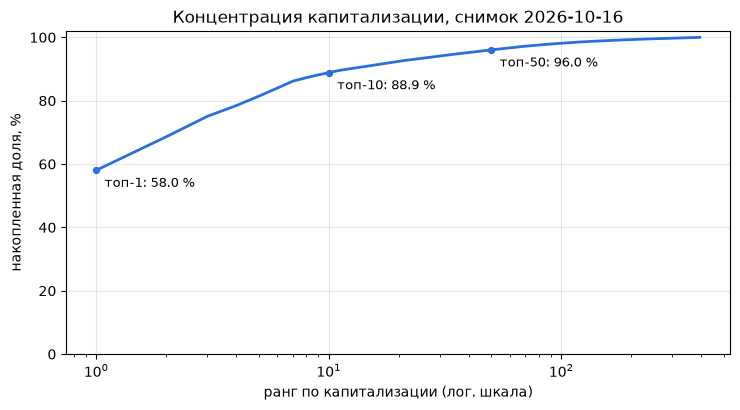

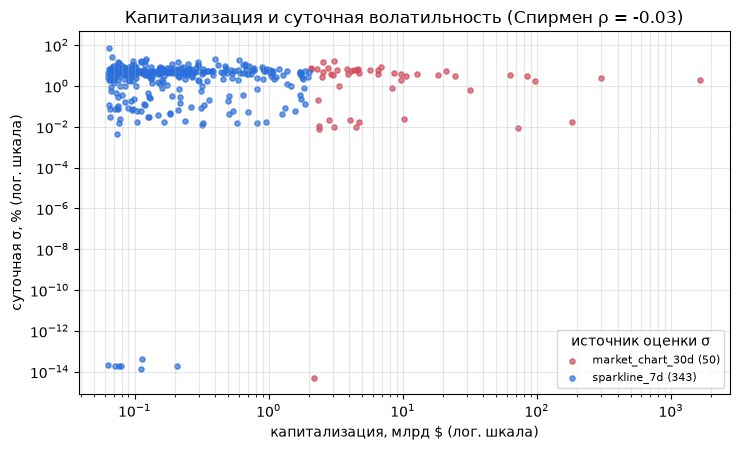

Графики сохранены: figures/mcap_concentration.png, figures/mcap_vs_volatility.png


In [26]:
import matplotlib
import matplotlib.pyplot as plt

Path("figures").mkdir(exist_ok=True)

# 1) Накопленная доля капитализации по рангу
cum = by_rank[["market_cap_rank", "mcap_share_pct"]].dropna().copy()
cum["cum_share_pct"] = cum["mcap_share_pct"].cumsum()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(cum["market_cap_rank"].astype(float), cum["cum_share_pct"], color="#2a6fdb", linewidth=2)
for r in (1, 10, 50):
    if r <= len(cum):
        y = float(cum["cum_share_pct"].iloc[r - 1])
        ax.scatter([r], [y], color="#2a6fdb", zorder=3, s=18)
        ax.annotate(f"топ-{r}: {y:.1f} %", (r, y), textcoords="offset points", xytext=(6, -12), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("ранг по капитализации (лог. шкала)")
ax.set_ylabel("накопленная доля, %")
ax.set_ylim(0, 102)
ax.set_title(f"Концентрация капитализации, снимок {snap_date}")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/mcap_concentration.png", dpi=150)
plt.show()

# 2) Капитализация ↔ суточная волатильность
pts = last.dropna(subset=["market_cap", "daily_volatility_pct"])
pts = pts[(pts["market_cap"] > 0) & (pts["daily_volatility_pct"] > 0)]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
colors = {"market_chart_30d": "#d1495b", "sparkline_7d": "#2a6fdb"}
for src, g in pts.groupby("vol_source"):
    ax.scatter(g["market_cap"] / 1e9, g["daily_volatility_pct"], s=14, alpha=0.7,
               color=colors.get(src, "#777777"), label=f"{src} ({len(g)})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("капитализация, млрд $ (лог. шкала)")
ax.set_ylabel("суточная σ, % (лог. шкала)")
ax.set_title(f"Капитализация и суточная волатильность (Спирмен ρ = {rho:.2f})")
ax.grid(alpha=0.3, which="both")
ax.legend(title="источник оценки σ", fontsize=8)
fig.tight_layout()
fig.savefig("figures/mcap_vs_volatility.png", dpi=150)
plt.show()
print("Графики сохранены: figures/mcap_concentration.png, figures/mcap_vs_volatility.png")

## Этап 12. Метрики для сравнения Python и n8n

Ячейка собирает измеренные значения Python-части из `state.json` и `collection_log.csv` и печатает таблицу для `report.md`.
Ячейка выполнялась до прогона n8n, поэтому замеры n8n и сверка с `nocode/nocode_result.csv` вынесены в этап 12б.

In [27]:
runs = pd.DataFrame(load_state()["runs"]).set_index("run_id")
full_runs = runs[runs["enriched"] > 0]          # «первый прогон дня»: с обогащением
r1 = full_runs.iloc[-1] if len(full_runs) else runs.loc[MAIN["run_id"]]
r2 = runs.loc[summary2["run_id"]]               # повторный прогон этого запуска блокнота
print("Полный прогон для сравнения:", r1.name, "| повторный:", r2.name)
log = pd.read_csv(LOG_PATH)
main_log = log[log["run_id"] == r1.name]
by_stage = main_log.groupby("stage").size().to_dict()

nocode_csv = Path("nocode") / "nocode_result.csv"
if nocode_csv.exists():
    n8n = pd.read_csv(nocode_csv, encoding="utf-8-sig")      # n8n пишет CSV с BOM
    n8n_rows = f"{len(n8n)} строк, уникальных coin_id: {n8n['coin_id'].nunique() if 'coin_id' in n8n else '—'}"
    common = set(n8n.get("coin_id", pd.Series(dtype=str)).astype(str)) & set(last["id"].astype(str))
    print(f"nocode_result.csv: {n8n_rows}; совпадает с Python-снимком по id: {len(common)}")
else:
    n8n_rows = "см. этап 12б"
    print("nocode/nocode_result.csv на момент выполнения ячейки не было — сверка с n8n в этапе 12б")

calls1, calls2 = int(r1["http_attempts"]), int(r2["http_attempts"])
comparison = pd.DataFrame([
    ("Число записей", f"{int(r1['unique_records'])} монет (+{int(r1['enriched'])} обогащены market_chart)", n8n_rows),
    ("Время прогона", f"{r1['duration_s']} с (первый за день); повторный — {r2['duration_s']} с",
     "см. этап 12б"),
    ("Пагинация", f"per_page/page, {int(r1['pages'])} стр., стоп по пустой/неполной странице, max_records, max_pages",
     "Loop Over Items по страницам [1, 2, 3] + Wait 6,5 с"),
    ("Ошибки / повторы", f"повторов {int(r1['retries'])}, 429: {int(r1['status_429'])}, 5xx: {int(r1['status_5xx'])}; "
     "Retry-After + backoff с джиттером, 4xx без повторов",
     "Retry On Fail: 5 попыток через 5 с при любой ошибке, Retry-After не учитывается; ветка ошибки → Stop and Error"),
    ("Воспроизводимость", "requirements.txt + run_real.sh, код в Git, state.json", "workflow.json (импорт), зависит от версии n8n"),
    ("Стоимость при 100 прогонах/мес", f"первый прогон дня — {calls1} запросов, повторный — {calls2}; "
     f"≈30 первых + 70 повторных = {30 * calls1 + 70 * calls2} вызовов/мес (верхняя граница {100 * calls1}; "
     "лимит Demo — 10 000/мес); 0 ₽", "3 запроса за прогон → 300 вызовов/мес; self-hosted 0 ₽"),
    ("Порог входа (1–5)", "4", "2"),
], columns=["Критерий", "Python (requests + pandas)", "n8n"])
print("HTTP-попыток первого прогона по этапам:", by_stage)
display(comparison)
print("\nТаблица для report.md:\n")
print(md_table(comparison))

print(f"\nПолнота полей сохранённого снимка {snap_date} ({len(last)} строк) для report.md:\n")
stored_cols = [c for c in CLEAN_COLUMNS if c in last.columns]
compl = pd.DataFrame({"поле": stored_cols, "тип": [str(last[c].dtype) for c in stored_cols],
                      "полнота, %": [round(float(last[c].notna().mean() * 100), 1) for c in stored_cols]})
print(md_table(compl))
print("\nПравила бизнес-логики (тот же снимок):\n")
print(md_table(business_rules(last)[0]))
print(f"\nДубликатов по ключу до дедупликации: {n_raw - len(df_snap)}; после: "
      f"{int(read_clean().duplicated(subset=KEY).sum())}")

Полный прогон для сравнения: run_20261016T120406237Z | повторный: run_20261016T121811006Z
nocode/nocode_result.csv на момент выполнения ячейки не было — сверка с n8n в этапе 12б
HTTP-попыток первого прогона по этапам: {'market_chart': 51, 'markets': 5}


,Критерий,Python (requests + pandas),n8n
0,Число записей,399 монет (+50 обогащены market_chart),см. этап 12б
1,Время прогона,844.8 с (первый за день); повторный — 59.0 с,см. этап 12б
2,Пагинация,"per_page/page, 4 стр., стоп по пустой/неполной...","Loop Over Items по страницам [1, 2, 3] + Wait ..."
3,Ошибки / повторы,"повторов 2, 429: 2, 5xx: 0; Retry-After + back...",Retry On Fail: 5 попыток через 5 с при любой о...
4,Воспроизводимость,"requirements.txt + run_real.sh, код в Git, sta...","workflow.json (импорт), зависит от версии n8n"
5,Стоимость при 100 прогонах/мес,"первый прогон дня — 56 запросов, повторный — 4...",3 запроса за прогон → 300 вызовов/мес; self-ho...
6,Порог входа (1–5),4,2



Таблица для report.md:

| Критерий | Python (requests + pandas) | n8n |
|---|---|---|
| Число записей | 399 монет (+50 обогащены market_chart) | см. этап 12б |
| Время прогона | 844.8 с (первый за день); повторный — 59.0 с | см. этап 12б |
| Пагинация | per_page/page, 4 стр., стоп по пустой/неполной странице, max_records, max_pages | Loop Over Items по страницам [1, 2, 3] + Wait 6,5 с |
| Ошибки / повторы | повторов 2, 429: 2, 5xx: 0; Retry-After + backoff с джиттером, 4xx без повторов | Retry On Fail: 5 попыток через 5 с при любой ошибке, Retry-After не учитывается; ветка ошибки → Stop and Error |
| Воспроизводимость | requirements.txt + run_real.sh, код в Git, state.json | workflow.json (импорт), зависит от версии n8n |
| Стоимость при 100 прогонах/мес | первый прогон дня — 56 запросов, повторный — 4; ≈30 первых + 70 повторных = 1960 вызовов/мес (верхняя граница 5600; лимит Demo — 10 000/мес); 0 ₽ | 3 запроса за прогон → 300 вызовов/мес; self-hosted 0 ₽ |
| Порог входа (1–5) | 4 | 2

## Этап 12б. Сверка с результатом n8n

Ячейка добавлена после прогона workflow в n8n (16.10.2026) и выполнена отдельно: этап 12 исполнялся раньше, чем появился
`nocode/nocode_result.csv`. Читает только файлы (`data_clean.csv`, `state.json`, `nocode/nocode_result.csv`,
`nocode/n8n_metrics.json` — замеры из Executions n8n), запросов к API не делает.

In [28]:
# Этап 12б: сверка n8n с Python-снимком и итоговая таблица сравнения (только чтение файлов)
import json
from pathlib import Path

import pandas as pd

n8n = pd.read_csv(Path("nocode") / "nocode_result.csv", encoding="utf-8-sig")   # n8n пишет CSV с BOM
metrics = json.loads((Path("nocode") / "n8n_metrics.json").read_text(encoding="utf-8"))
clean = pd.read_csv("data_clean.csv")
snap = str(n8n["snapshot_date"].iloc[0])
py_snap = clean[clean["snapshot_date"].astype(str) == snap]

common = set(n8n["coin_id"]) & set(py_snap["id"])
print(f"n8n: {len(n8n)} строк, уникальных coin_id: {n8n['coin_id'].nunique()}, снимок {snap}, "
      f"пустых значений: {int(n8n.isna().sum().sum())}")
print(f"Python-снимок того же дня: {len(py_snap)} строк; общих монет: {len(common)} из {n8n['coin_id'].nunique()}")

both = n8n.merge(py_snap[["id", "market_cap_rank", "current_price"]], left_on="coin_id", right_on="id")
ranked = both.dropna(subset=["market_cap_rank"])
d_rank = (ranked["rank"] - ranked["market_cap_rank"]).abs()
d_price = (both["price_usd"] / both["current_price"] - 1).abs() * 100
print(f"Ранг совпал у {int((d_rank == 0).sum())} из {len(ranked)} монет; медиана |Δ ранга| {d_rank.median():.0f}, "
      f"максимум {d_rank.max():.0f}; медиана |Δ цены| {d_price.median():.2f} % — снимки сняты с разницей ≈ 1 ч")

runs = pd.DataFrame(json.loads(Path("state.json").read_text(encoding="utf-8"))["runs"]).set_index("run_id")
r1, r2 = runs[runs["enriched"] > 0].iloc[-1], runs.iloc[-1]
ok = [e for e in metrics["executions"] if e["status"] == "success"]
err = [e for e in metrics["executions"] if e["status"] == "error"]
n8n_time = " и ".join(f"{e['duration_s']} с" for e in ok)
n8n_retries = sum(e["retries_estimated"] for e in ok)

rows = [
    ("Число записей", f"{int(r1['unique_records'])} монет (+{int(r1['enriched'])} обогащены market_chart)",
     f"{len(n8n)} монет (3 страницы × 100)"),
    ("Время прогона", f"{r1['duration_s']} с (первый за день); повторный — {r2['duration_s']} с",
     f"{n8n_time} ({len(ok)} успешных запуска; {metrics['wait_s_per_run']} с — паузы Wait)"),
    ("HTTP-запросов за прогон", f"{int(r1['http_attempts'])} (первый), {int(r2['http_attempts'])} (повторный)",
     f"{ok[0]['http_requests']} + повторы"),
    ("Повторы в реальных прогонах", f"{int(r1['retries'])} (429: {int(r1['status_429'])}, 5xx: {int(r1['status_5xx'])})",
     f"{n8n_retries} (сетевой сбой); демонстрация 404: {err[0]['http_requests']} попыток" if err else f"{n8n_retries}"),
    ("Версия среды", "Python 3.13.7, requests + pandas", f"n8n {metrics['n8n_version']}, Node.js {metrics['node_version']}"),
]


def md(rows, head):
    out = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    out += ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    return "\n".join(out)


print("\nТаблица для report.md (измеренные строки):\n")
print(md(rows, ["Критерий", "Python (requests + pandas)", "n8n"]))


n8n: 300 строк, уникальных coin_id: 300, снимок 2026-10-16, пустых значений: 6
Python-снимок того же дня: 401 строк; общих монет: 300 из 300
Ранг совпал у 156 из 297 монет; медиана |Δ ранга| 0, максимум 12; медиана |Δ цены| 0.57 % — снимки сняты с разницей ≈ 1 ч

Таблица для report.md (измеренные строки):

| Критерий | Python (requests + pandas) | n8n |
|---|---|---|
| Число записей | 399 монет (+50 обогащены market_chart) | 300 монет (3 страницы × 100) |
| Время прогона | 844.8 с (первый за день); повторный — 59.0 с | 28.5 с и 22.7 с (2 успешных запуска; 19.5 с — паузы Wait) |
| HTTP-запросов за прогон | 56 (первый), 4 (повторный) | 3 + повторы |
| Повторы в реальных прогонах | 2 (429: 2, 5xx: 0) | 1 (сетевой сбой); демонстрация 404: 5 попыток |
| Версия среды | Python 3.13.7, requests + pandas | n8n 2.35.7, Node.js 24.22.0 |


## Итоги

- Собрано ≥ 300 записей `/coins/markets` за ≥ 3 страницы с предохранителями, паузами и обработкой 429/5xx; журнал — в `collection_log.csv`.
- Вложенный объект `roi` развёрнут через `json_normalize(sep="_")`, вложенный массив `sparkline_in_7d.price` — через
  `record_path` + `meta`; топ-50 обогащены 30-дневной историей `/market_chart`, число строк до и после `merge` совпадает.
- Качество: полнота полей, дубликаты по ключу, типы, 7 правил бизнес-логики (флаги в `qc_flags`).
- Повторный запуск в тот же день добавляет только монеты, вошедшие в топ-400 между запусками (в прогоне 16.10.2026 — 2),
  и не тратит запросы на обогащение (водяной знак в `state.json`).
- Ключ API (если используется) берётся только из окружения и не попадает ни в код, ни в журнал, ни в вывод.

*Data provided by CoinGecko — Powered by CoinGecko.*